# Анализ удержания пользователей платформы IT Resume

## Цель и задачи исследования

IT Resume работает по подписочной модели, поэтому для платформы важно не только привлекать новых пользователей, но и понимать, возвращаются ли они после регистрации и продолжают ли пользоваться продуктом.

**Цель исследования** — изучить удержание пользователей IT Resume, определить, на каком этапе происходит основной отток, и выяснить, какие особенности поведения в первые дни связаны с дальнейшим возвращением на платформу.

Для этого необходимо:

1. Рассчитать основные показатели retention и построить кривую удержания.
2. Сравнить retention пользователей разных когорт регистрации.
3. Определить, в какой момент после регистрации происходит основной отток.
4. Изучить поведение пользователей в первые дни после регистрации.
5. Проверить, как с D7 retention связаны:
   - регулярность активности в первые три дня;
   - начало работы с задачами в первые три дня;
   - получение первого успешного решения в первые три дня;
   - количество неуспешных попыток до первого успеха;
   - сложность первой задачи;
   - использование разных разделов платформы;
   - использование CodeCoins в первые три дня;
   - время до первого успешного решения.
6. На основе результатов определить основные точки роста retention.
7. Сформулировать продуктовые рекомендации и показатели для дальнейшего мониторинга.

## Описание данных

Для исследования используется база данных платформы IT Resume. Основные таблицы, которые понадобятся в анализе:

- `users` — данные о зарегистрированных пользователях и дата регистрации;
- `userentry` — первый зафиксированный вход пользователя на платформу за каждый день; эта таблица используется для расчёта retention;
- `coderun` — запуски кода при работе с задачами;
- `codesubmit` — отправки решений на проверку и их результат;
- `problem` — информация о задачах, в том числе уровень сложности;
- `teststart` — начало прохождения тестов;
- `transaction` и `transactiontype` — операции с внутренней валютой CodeCoins.

Перед расчётом retention необходимо проверить период, за который доступны данные, качество связей между таблицами и ограничения, которые могут повлиять на результаты.

## Гипотезы исследования

В рамках исследования проверим несколько гипотез о том, какое поведение пользователей в первые дни связано с их возвращением на платформу..

- **H1.** Чем больше дней пользователь активен в период D0–D2, тем выше его D7 retention.
- **H2.** Начало работы с задачами в первые три дня связано с более высоким D7 retention.
- **H3.** Получение успешного решения в D0–D2 связано с более высоким D7 retention.
- **H4.** Большое количество неуспешных попыток до первого успешного решения связано с более низким D7 retention.
- **H5.** Более высокая сложность первой задачи связана с более низким D7 retention.
- **H6.** Использование нескольких разделов платформы в D0–D2 связано с более высоким D7 retention.
- **H7.** Использование CodeCoins для доступа к контенту в первые три дня связано с более высоким D7 retention.
- **H8.** Более короткое время до первого успешного решения связано с более высоким D7 retention.

<a id='toc'></a>

## Содержание

1. [Подготовка и проверка данных](#data-preparation)
2. [Общая картина](#overview)
3. [Базовый retention](#retention)
   - 3.1. [Динамика retention](#retention-dynamics)
   - 3.2. [Rolling retention](#rolling-retention)
4. [Когортный анализ retention](#cohort-retention)
5. [Проверка гипотез](#hypotheses)
   - 5.1. [H1. Активность в D0–D2](#h1)
   - 5.2. [H2. Начало работы с задачами в первые три дня](#h2)
   - 5.3. [H3. Первое успешное решение в первые три дня](#h3)
   - 5.4. [H4. Неуспешные попытки до первого успеха](#h4)
   - 5.5. [H5. Сложность первой задачи](#h5)
   - 5.6. [H6. Использование разделов платформы](#h6)
   - 5.7. [H7. Использование CodeCoins](#h7)
   - 5.8. [H8. Время до первого успешного решения](#h8)
6. [Основные результаты исследования](#results)
7. [Выводы](#conclusions)
8. [Продуктовые рекомендации](#recommendations)

# Анализ данных

<a id='data-preparation'></a>

## 1. Подготовка и проверка данных

### Подготовка окружения

Импортируем библиотеки для работы с данными, подключения к PostgreSQL, статистических тестов и построения графиков.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from dotenv import load_dotenv
from matplotlib import colors
from scipy.stats import chi2_contingency, mannwhitneyu
from sqlalchemy import create_engine

In [2]:
# Загружаем параметры подключения к БД.
load_dotenv(Path.cwd().parent / '.env')

# Создаём подключение к PostgreSQL.
engine = create_engine(
    'postgresql+psycopg2://'
    f'{os.getenv("DB_USER")}:{os.getenv("DB_PASSWORD")}'
    f'@{os.getenv("DB_HOST")}:{os.getenv("DB_PORT")}'
    f'/{os.getenv("DB_NAME")}'
)

# Загружаем JupySQL.
%load_ext sql
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%config SqlMagic.named_parameters = 'disabled'

# Используем это же подключение для выполнения SQL-запросов в ноутбуке.
%sql engine

In [3]:
# Папка для сохранения графиков исследования.
figures_dir = Path('../reports/figures')
figures_dir.mkdir(parents=True, exist_ok=True)

In [4]:
%%sql

-- Сначала посмотрим, за какой период доступны данные и сколько пользователей представлено в основных таблицах.
-- Это поможет определить границы анализа и не считать retention там, где для пользователя ещё нет
-- достаточного периода наблюдения.
SELECT
    'userentry' AS table_name,
    DATE_TRUNC('second', MIN(entry_at)) AS first_event,
    DATE_TRUNC('second', MAX(entry_at)) AS last_event,
    COUNT(*) AS events,
    COUNT(DISTINCT user_id) AS users
FROM userentry

UNION ALL

SELECT
    'coderun',
    DATE_TRUNC('second', MIN(created_at)),
    DATE_TRUNC('second', MAX(created_at)),     
    COUNT(*),
    COUNT(DISTINCT user_id)
FROM coderun

UNION ALL

SELECT
    'codesubmit',
    DATE_TRUNC('second', MIN(created_at)),
    DATE_TRUNC('second', MAX(created_at)),
    COUNT(*),
    COUNT(DISTINCT user_id)
FROM codesubmit

ORDER BY table_name;

table_name,first_event,last_event,events,users
coderun,2021-03-27 17:55:11,2022-05-17 09:03:57,55722,868
codesubmit,2021-03-28 13:00:45,2022-05-17 09:29:58,23768,861
userentry,2021-03-29 02:54:14,2022-05-24 23:10:52,7995,2757


#### Промежуточный вывод

В исходных данных события охватывают период с марта 2021 года по май 2022 года. При этом периоды в таблицах различаются: записи о входах пользователей продолжаются до 24 мая, а данные о работе с задачами — до 17 мая.

Также видно, что первые события в `coderun` и `codesubmit` появились раньше первых записей в `userentry`. Это нужно проверить отдельно, прежде чем определять рабочий период исследования.

При расчете retention важно учитывать, сколько времени прошло с момента регистрации пользователя до последней доступной даты наблюдения. Например, D30 можно рассчитать только для пользователей, которые зарегистрировались не менее чем за 30 дней до конца периода наблюдения.

In [5]:
%%sql

-- В предыдущем запросе события с задачами появились раньше первых записей о входах на платформу.
-- Проверим, каким пользователям принадлежат эти события и как они соотносятся с датами регистрации.

WITH first_activity AS (
    SELECT
        user_id,
        MIN(created_at) AS first_task_activity
    FROM (
        SELECT user_id, created_at
        FROM coderun

        UNION ALL

        SELECT user_id, created_at
        FROM codesubmit
    ) AS task_events
    GROUP BY user_id
),

first_entry AS (
    SELECT
        user_id,
        MIN(entry_at) AS first_entry
    FROM userentry
    GROUP BY user_id
)

SELECT
    fa.user_id,
    DATE_TRUNC('second', u.date_joined) AS date_joined,
    DATE_TRUNC('second', fa.first_task_activity) AS first_task_activity,
    DATE_TRUNC('second', fe.first_entry) AS first_entry,
    fe.first_entry::date - fa.first_task_activity::date AS days_difference
FROM first_activity AS fa
JOIN users AS u
    ON u.id = fa.user_id
LEFT JOIN first_entry AS fe
    ON fe.user_id = fa.user_id
WHERE fa.first_task_activity < (
    SELECT MIN(entry_at)
    FROM userentry
)
ORDER BY fa.first_task_activity;

user_id,date_joined,first_task_activity,first_entry,days_difference
20,2021-04-19 07:46:43,2021-03-27 17:55:11,2021-04-05 12:29:11,9
19,2021-04-22 15:37:33,2021-03-28 02:18:47,2021-03-29 13:49:41,1
15,2021-03-29 03:58:58,2021-03-28 13:00:45,2021-03-29 02:54:14,1


#### Исключение технических пользователей

По описанию учебной базы в заданиях на платформе пользователи с `id <= 94` являются техническими и не должны участвовать в анализе.

Проверка предыдущего запроса это подтверждает: все события с задачами, которые появились раньше первых записей в `userentry`, относятся к пользователям с `id <= 94`. У одного из них активность с задачами зафиксирована даже раньше даты регистрации.

Поэтому далее во всех расчётах учитываем только пользователей с `id > 94`.

In [6]:
%%sql

-- После исключения технических пользователей еще раз проверим период данных.
-- Теперь эти даты будем использовать как реальные границы исследования.

SELECT
    'userentry' AS table_name,
    DATE_TRUNC('second', MIN(entry_at)) AS first_event,
    DATE_TRUNC('second', MAX(entry_at)) AS last_event,
    COUNT(*) AS events,
    COUNT(DISTINCT user_id) AS users
FROM userentry
WHERE user_id > 94

UNION ALL

SELECT
    'coderun',
    DATE_TRUNC('second', MIN(created_at)),
    DATE_TRUNC('second', MAX(created_at)),
    COUNT(*),
    COUNT(DISTINCT user_id)
FROM coderun
WHERE user_id > 94

UNION ALL

SELECT
    'codesubmit',
    DATE_TRUNC('second', MIN(created_at)),
    DATE_TRUNC('second', MAX(created_at)),
    COUNT(*),
    COUNT(DISTINCT user_id)
FROM codesubmit
WHERE user_id > 94

ORDER BY table_name;

table_name,first_event,last_event,events,users
coderun,2021-11-20 10:26:46,2022-05-17 09:03:57,53928,843
codesubmit,2021-11-20 10:27:58,2022-05-17 09:29:58,21155,836
userentry,2021-11-20 10:15:12,2022-05-24 23:10:52,7566,2723


#### Промежуточный вывод

После исключения технических пользователей картина меняется: первые события в `userentry`, `coderun` и `codesubmit` относятся к 20 ноября 2021 года.

Поэтому дальнейший анализ проводим только для пользователей с `id > 94`. Рабочий период начинается 20 ноября 2021 года.

In [7]:
%%sql

-- Посмотрим, за какой период в users есть регистрации и сколько реальных пользователей вошло в исследование.

SELECT
    DATE_TRUNC('second', MIN(date_joined)) AS first_registration,
    DATE_TRUNC('second', MAX(date_joined)) AS last_registration,
    COUNT(*) AS users
FROM users
WHERE id > 94;

first_registration,last_registration,users
2021-11-20 10:14:11,2022-04-21 12:20:00,2695


In [8]:
%%sql registrations_by_month <<

-- Посмотрим, как менялось количество регистраций по месяцам и насколько оно изменилось
-- относительно предыдущего месяца.

WITH monthly_registrations AS (
    SELECT
        DATE_TRUNC('month', date_joined)::date AS registration_month,
        COUNT(*) AS registrations
    FROM users
    WHERE id > 94
    GROUP BY registration_month
)

SELECT
    registration_month,
    registrations,
    ROUND(
        (
            registrations * 1.0
            / NULLIF(
                LAG(registrations) OVER (ORDER BY registration_month),
                0
            )
            - 1
        ) * 100,
        2
    ) AS growth_pct
FROM monthly_registrations
ORDER BY registration_month;

In [9]:
df_registrations_by_month = registrations_by_month.DataFrame()

df_registrations_by_month['registration_month'] = pd.to_datetime(
    df_registrations_by_month['registration_month']
)

df_registrations_by_month

,registration_month,registrations,growth_pct
0,2021-11-01,187,None
1,2021-12-01,132,-29.41
2,2022-01-01,602,356.06
3,2022-02-01,1058,75.75
4,2022-03-01,479,-54.73
5,2022-04-01,237,-50.52


Количество регистраций заметно менялось от месяца к месяцу, поэтому посмотрим на динамику визуально. Это также поможет оценить размеры когорт, которые дальше будем сравнивать при анализе retention.

/var/folders/8j/ztl002_95lj8cg7sxs1tl67w0000gn/T/ipykernel_52372/1156610880.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(


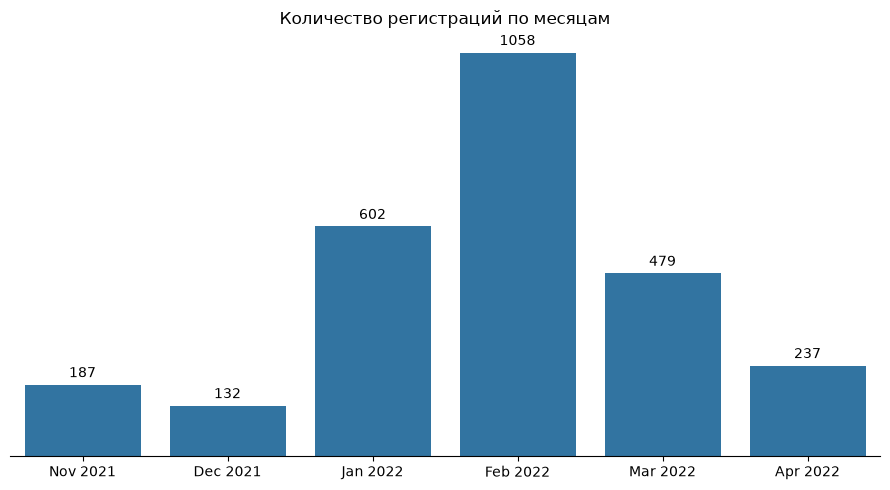

In [10]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=df_registrations_by_month,
    x='registration_month',
    y='registrations'
)

ax.set_xticklabels(
    df_registrations_by_month['registration_month'].dt.strftime('%b %Y')
)

ax.bar_label(
    ax.containers[0],
    padding=3
)

plt.title('Количество регистраций по месяцам')
plt.xlabel('')
plt.ylabel('')
plt.yticks([])

sns.despine(left=True)

plt.tight_layout()

plt.savefig(
    figures_dir / 'registrations_by_month.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

#### Промежуточный вывод

Количество регистраций заметно менялось в течение исследуемого периода. После 132 регистраций в декабре, в январе их число выросло до 602, а максимум пришёлся на февраль — **1 058 пользователей**.

После февральского пика количество регистраций снизилось до 479 в марте и 237 в апреле.

Размеры месячных когорт сильно различаются, поэтому дальше важно сравнить не только количество привлечённых пользователей, но и их retention. Причины резких изменений числа регистраций определить по имеющимся данным нельзя: информации об источниках привлечения и маркетинговых кампаниях в базе нет.

In [11]:
%%sql

-- Перед расчетом retention проверим, все ли user_id из userentry можно связать
-- с зарегистрированными пользователями из users.

SELECT
    COUNT(DISTINCT ue.user_id) AS users_without_user_record,
    COUNT(*) AS entries_without_user_record,
    DATE_TRUNC('second', MIN(ue.entry_at)) AS first_entry,
    DATE_TRUNC('second', MAX(ue.entry_at)) AS last_entry
FROM userentry AS ue
LEFT JOIN users AS u
    ON ue.user_id = u.id
WHERE ue.user_id > 94
    AND u.id IS NULL;

users_without_user_record,entries_without_user_record,first_entry,last_entry
414,911,2022-04-21 13:49:19,2022-05-24 23:10:52


In [12]:
%%sql

-- Теперь проверим обратную ситуацию:
-- сколько зарегистрированных пользователей вообще не имеют записей в userentry.

SELECT
    COUNT(*) AS users_without_entry
FROM users AS u
LEFT JOIN userentry AS ue
    ON u.id = ue.user_id
WHERE u.id > 94
    AND ue.user_id IS NULL;

users_without_entry
386


#### Какие данные используем для расчета retention

После исключения технических записей в `users` остаётся **2 695 зарегистрированных пользователей**.

При сравнении `users` и `userentry` обнаружились два случая:

- у **386 зарегистрированных пользователей** нет ни одной записи в `userentry`;
- в `userentry` есть **414 user_id**, которых нет в таблице `users`.

Пользователей без записи в `users` исключаем: для них неизвестна дата регистрации, поэтому невозможно определить, на какой день после регистрации произошло событие.

При этом 386 зарегистрированных пользователей без записей в `userentry` оставляем в анализе. Они относятся к реальным регистрациям, а отсутствие последующей активности важно учитывать при расчёте retention.

Таким образом, основой исследования будут 2 695 пользователей из `users` с `id > 94`, а события из `userentry` будем учитывать только для этих пользователей.

### Определение Day 0

Для расчета retention сначала нужно определить точку отсчета. Сравним дату регистрации пользователя с датой его первого зафиксированного входа на платформу.

In [13]:
%%sql

-- Проверяем, через сколько дней после регистрации был зафиксирован первый вход пользователя.

WITH first_entries AS (
    SELECT
        user_id,
        MIN(entry_at) AS first_entry
    FROM userentry
    GROUP BY user_id
)

SELECT
    fe.first_entry::date - u.date_joined::date AS days_to_first_entry,
    COUNT(*) AS users
FROM users AS u
JOIN first_entries AS fe
    ON u.id = fe.user_id
WHERE u.id > 94
GROUP BY days_to_first_entry
ORDER BY days_to_first_entry;

days_to_first_entry,users
0,2260
1,18
2,3
3,4
4,1
5,2
6,1
7,1
8,2
10,1


In [14]:
%%sql

-- Дополнительно проверим, нет ли пользователей, у которых первый вход записан раньше даты регистрации.

WITH first_entries AS (
    SELECT
        user_id,
        MIN(entry_at) AS first_entry
    FROM userentry
    GROUP BY user_id
)

SELECT
    u.id AS user_id,
    DATE_TRUNC('second', u.date_joined) AS date_joined,
    DATE_TRUNC('second', fe.first_entry) AS first_entry,
    fe.first_entry::date - u.date_joined::date AS days_difference
FROM users AS u
JOIN first_entries AS fe
    ON u.id = fe.user_id
WHERE u.id > 94
    AND fe.first_entry < u.date_joined
ORDER BY days_difference, u.id;

user_id,date_joined,first_entry,days_difference


#### Вывод

Из 2 309 пользователей, имеющих записи в `userentry`, у 2 260 первый вход зафиксирован в день регистрации. Случаев, когда вход произошел раньше регистрации, не обнаружено.

Поэтому за **Day 0 возьмем календарную дату регистрации пользователя (`date_joined`)**.

Возвращением на день N будем считать наличие записи в `userentry` ровно через N календарных дней после регистрации.

In [15]:
%%sql

-- Проверим, как пользователи без записей в userentry распределены по месяцам регистрации.

SELECT
    DATE_TRUNC('month', u.date_joined)::date AS registration_month,
    COUNT(*) AS registrations,
    COUNT(*) FILTER (WHERE ue.user_id IS NULL) AS users_without_entry,
    ROUND(
        COUNT(*) FILTER (WHERE ue.user_id IS NULL) * 100.0 / COUNT(*),
        2
    ) AS without_entry_pct
FROM users AS u
LEFT JOIN (
    SELECT DISTINCT user_id
    FROM userentry
) AS ue
    ON u.id = ue.user_id
WHERE u.id > 94
GROUP BY registration_month
ORDER BY registration_month;

registration_month,registrations,users_without_entry,without_entry_pct
2021-11-01,187,11,5.88
2021-12-01,132,11,8.33
2022-01-01,602,104,17.28
2022-02-01,1058,167,15.78
2022-03-01,479,64,13.36
2022-04-01,237,29,12.24


### Итоги проверки данных

После исключения технических пользователей в исследование входят **2 695 пользователей**, зарегистрированных с 20 ноября 2021 года по 21 апреля 2022 года.

Для расчета retention используем следующие правила:

- учитываем пользователей из `users` с `id > 94`;
- Day 0 — календарная дата регистрации (`date_joined`);
- возвращением на день N считаем наличие записи в `userentry` ровно через N календарных дней после регистрации;
- 386 зарегистрированных пользователей без записей в `userentry` остаются в анализе;
- 414 `user_id` из `userentry`, которых нет в `users`, исключаем, так как для них неизвестна дата регистрации;
- для каждого показателя retention учитываем только пользователей, для которых нужное количество дней после регистрации уже прошло.

Основное ограничение данных — таблицы `users` и `userentry` охватывают разные периоды: регистрации в `users` заканчиваются 21 апреля 2022 года, а события в `userentry` продолжаются до 24 мая.


[Вернуться к содержанию](#toc)

<a id='overview'></a>

## 2. Общая картина

Перед расчетом retention рассмотрим динамику привлечения пользователей и общую активность на платформе. Это позволит понять масштаб аудитории и контекст, в котором формировались исследуемые когорты.

Перед анализом работы с задачами проверим значения поля `is_false` в `codesubmit`. По описанию данных значение `0` соответствует успешной отправке решения, а `1` — неуспешной.

In [16]:
%%sql

-- Проверяем количество успешных и неуспешных отправок решений.

SELECT
    is_false,
    COUNT(*) AS submits
FROM codesubmit AS cs
JOIN users AS u
    ON u.id = cs.user_id
WHERE u.id > 94
GROUP BY is_false
ORDER BY is_false;

is_false,submits
0,8241
1,12914


### 2.1. Использование основных разделов платформы

Перед расчетом retention посмотрим, какая часть зарегистрированных пользователей хотя бы раз входила на платформу, работала с задачами и начинала тесты.

In [17]:
%%sql activity_coverage <<

-- Считаем, сколько зарегистрированных пользователей хотя бы раз совершали основные действия на платформе.
-- В каждой таблице сначала оставляем уникальных пользователей, чтобы один пользователь учитывался
-- только один раз.

WITH base_users AS (
    SELECT id
    FROM users
    WHERE id > 94
),

entry_users AS (
    SELECT DISTINCT user_id
    FROM userentry
),

run_users AS (
    SELECT DISTINCT user_id
    FROM coderun
),

submit_users AS (
    SELECT DISTINCT user_id
    FROM codesubmit
),

successful_users AS (
    SELECT DISTINCT user_id
    FROM codesubmit
    WHERE is_false = 0
),

test_users AS (
    SELECT DISTINCT user_id
    FROM teststart
)

SELECT
    COUNT(*) AS registered_users,
    COUNT(e.user_id) AS users_with_entry,
    COUNT(r.user_id) AS users_with_run,
    COUNT(s.user_id) AS users_with_submit,
    COUNT(ss.user_id) AS users_with_successful_submit,
    COUNT(t.user_id) AS users_with_test_start
FROM base_users AS b
LEFT JOIN entry_users AS e
    ON b.id = e.user_id
LEFT JOIN run_users AS r
    ON b.id = r.user_id
LEFT JOIN submit_users AS s
    ON b.id = s.user_id
LEFT JOIN successful_users AS ss
    ON b.id = ss.user_id
LEFT JOIN test_users AS t
    ON b.id = t.user_id;

In [18]:
df_activity_coverage = activity_coverage.DataFrame()
df_activity_coverage

,registered_users,users_with_entry,users_with_run,users_with_submit,users_with_successful_submit,users_with_test_start
0,2695,2309,843,836,706,1197


Для наглядности сравним, какая доля всех зарегистрированных пользователей совершала каждое из рассматриваемых действий хотя бы один раз за доступный период.

Результат SQL содержит по одному столбцу для каждого действия. Для построения графика преобразуем таблицу в длинный формат: каждой строке будет соответствовать одно действие, количество пользователей и их доля от всех зарегистрированных.

In [19]:
coverage = df_activity_coverage.melt(
    var_name='activity',
    value_name='users'
)

coverage['activity'] = coverage['activity'].map({
    'registered_users': 'Регистрация',
    'users_with_entry': 'Вход на платформу',
    'users_with_run': 'Запуск кода',
    'users_with_submit': 'Отправка решения',
    'users_with_successful_submit': 'Успешное решение',
    'users_with_test_start': 'Начало теста'
})

registered_users = df_activity_coverage.loc[0, 'registered_users']

coverage['users_pct'] = (
    coverage['users'] / registered_users * 100
).round(1)

coverage

,activity,users,users_pct
0,Регистрация,2695,100.0
1,Вход на платформу,2309,85.7
2,Запуск кода,843,31.3
3,Отправка решения,836,31.0
4,Успешное решение,706,26.2
5,Начало теста,1197,44.4


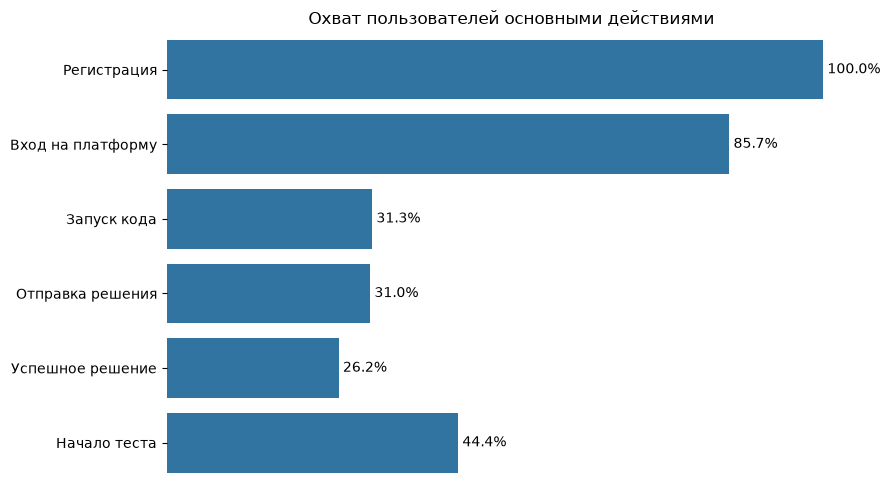

In [20]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=coverage,
    x='users_pct',
    y='activity'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3
    )

plt.title('Охват пользователей основными действиями')
plt.xlabel('')
plt.ylabel('')
plt.xticks([])

sns.despine(bottom=True, left=True)

plt.tight_layout()

plt.savefig(
    figures_dir / 'user_activity_coverage.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

#### Промежуточный вывод

Из 2 695 зарегистрированных пользователей у 2 309 (85.7%) есть хотя бы один зафиксированный вход на платформу.

С задачами работала примерно треть пользователей: 843 (31.3%) хотя бы раз запускали код, 836 (31.0%) отправляли решение на проверку, а 706 (26.2%) получили хотя бы одно успешное решение.

Тесты начинали 1 197 (44.4%) пользователей, то есть этот раздел использовала большая доля зарегистрированных пользователей, чем раздел с задачами.

При этом эти показатели нельзя рассматривать как последовательную воронку: работа с задачами и прохождение тестов — разные сценарии использования платформы, которые могут пересекаться. Далее проверим, как ранняя активность в этих разделах связана с D7 retention.

In [21]:
%%sql

-- Проверим, всегда ли CodeSubmit происходит после CodeRun.
-- Это нужно, чтобы понять, можно ли считать эти действия последовательными этапами работы с задачей.

SELECT
    COUNT(DISTINCT cs.user_id) AS submit_without_run
FROM codesubmit AS cs
JOIN users AS u
    ON u.id = cs.user_id
LEFT JOIN (
    SELECT DISTINCT user_id
    FROM coderun
) AS cr
    ON cs.user_id = cr.user_id
WHERE u.id > 94
    AND cr.user_id IS NULL;

submit_without_run
55


#### Особенность работы с задачами

У 55 пользователей есть `CodeSubmit`, но нет ни одного зафиксированного `CodeRun`.

Поэтому `CodeRun → CodeSubmit → успешный CodeSubmit` нельзя считать строгой последовательностью действий для всех пользователей. В дальнейшем эти события будем рассматривать отдельно.

### 2.2. Частота активности пользователей

Теперь посмотрим, сколько разных дней пользователи были активны на платформе за весь доступный период. Это позволит оценить, насколько часто пользователи возвращались после регистрации.

In [22]:
%%sql active_days_distribution <<

-- Посмотрим, сколько дней пользователи были активны на платформе за весь доступный период.
-- Пользователям без записей в userentry присваиваем 0 активных дней.

WITH user_activity AS (
    SELECT
        u.id AS user_id,
        COUNT(DISTINCT ue.entry_at::date) AS active_days
    FROM users AS u
    LEFT JOIN userentry AS ue
        ON u.id = ue.user_id
    WHERE u.id > 94
    GROUP BY u.id
)

SELECT
    active_days,
    COUNT(*) AS users,
    ROUND(
        COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
        2
    ) AS users_pct
FROM user_activity
GROUP BY active_days
ORDER BY active_days;

In [23]:
df_active_days = active_days_distribution.DataFrame()
df_active_days

,active_days,users,users_pct
0,0,386,14.32
1,1,1383,51.32
2,2,379,14.06
3,3,150,5.57
4,4,100,3.71
5,5,58,2.15
6,6,38,1.41
7,7,29,1.08
8,8,19,0.71
9,9,13,0.48


Распределение количества активных дней имеет длинный хвост: максимальное значение достигает 95 дней, но при больших значениях в каждой группе остаётся очень мало пользователей.

Чтобы график оставался читаемым, отдельно покажем пользователей с 0–10 активными днями, а пользователей с 11 и более днями объединим в группу `11+`.

In [24]:
# Объединяем пользователей с более чем 10 активными днями в одну группу, чтобы длинный хвост
# не растягивал график.

df_active_days_plot = df_active_days.copy()

df_active_days_plot['active_days_group'] = np.where(
    df_active_days_plot['active_days'] > 10,
    '11+',
    df_active_days_plot['active_days'].astype(str)
)

df_active_days_plot = (
    df_active_days_plot
    .groupby('active_days_group', as_index=False)['users']
    .sum()
)

# Рассчитываем долю пользователей в каждой группе.
df_active_days_plot['users_pct'] = (
    df_active_days_plot['users']
    / df_active_days_plot['users'].sum()
    * 100
).round(2)

category_order = [str(day) for day in range(11)] + ['11+']

df_active_days_plot['active_days_group'] = pd.Categorical(
    df_active_days_plot['active_days_group'],
    categories=category_order,
    ordered=True
)

df_active_days_plot = df_active_days_plot.sort_values('active_days_group')

df_active_days_plot

,active_days_group,users,users_pct
0,0,386,14.32
1,1,1383,51.32
4,2,379,14.06
5,3,150,5.57
6,4,100,3.71
7,5,58,2.15
8,6,38,1.41
9,7,29,1.08
10,8,19,0.71
11,9,13,0.48


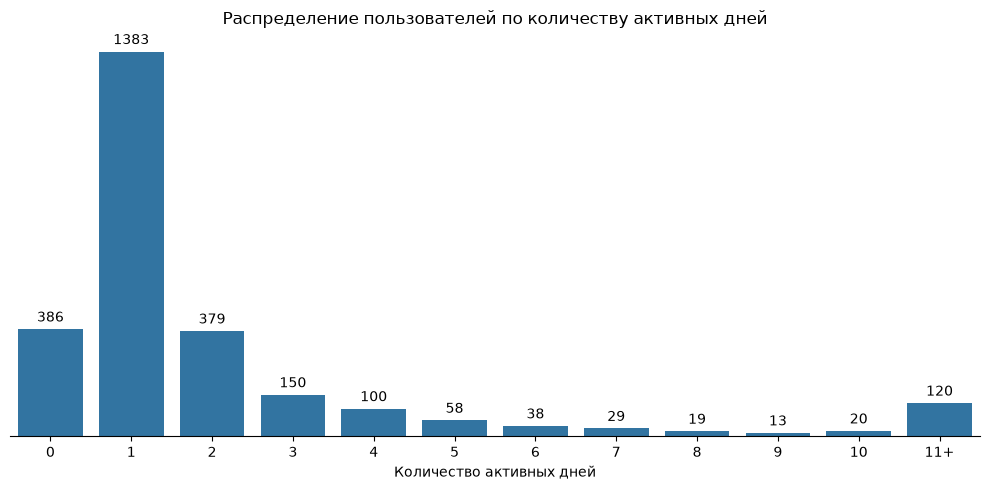

In [25]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=df_active_days_plot,
    x='active_days_group',
    y='users'
)

ax.bar_label(
    ax.containers[0],
    padding=3
)

plt.title('Распределение пользователей по количеству активных дней')
plt.xlabel('Количество активных дней')
plt.ylabel('')
plt.yticks([])

sns.despine(left=True)

plt.tight_layout()

plt.savefig(
    figures_dir / 'active_days_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

#### Частота возвращений пользователей

Большинство зарегистрированных пользователей были активны на платформе всего несколько дней. У 386 пользователей (14,32%) нет ни одного зафиксированного активного дня, а 1 383 пользователя (51,32%) были активны только один день.

В сумме **65,64% пользователей имеют не более одного активного дня, а 79,70% — не более двух**.

Это показывает, что большая часть аудитории практически не возвращается на платформу. Однако по количеству активных дней нельзя определить, когда именно происходит основной отток. Поэтому дальше рассчитаем retention по конкретным дням после регистрации.

[Вернуться к содержанию](#toc)

<a id='retention'></a>

## 3. Базовый retention

Для оценки удержания рассчитаем N-day retention для D0, D1, D3, D7, D14, D30, D60 и D90.

Пользователь считается вернувшимся на день N, если в `userentry` есть запись о его входе ровно через N календарных дней после даты регистрации.

**D(N) Retention = количество пользователей, вернувшихся на день N / количество пользователей, для которых день N уже наступил × 100%**

D0 показывает долю зарегистрированных пользователей, у которых вход в `userentry` зафиксирован непосредственно в день регистрации. Для D1–D90 учитываем только пользователей, для которых соответствующее количество дней после регистрации уже прошло.

In [26]:
%%sql

-- Рассчитываем retention в ключевые дни после регистрации.
-- Пользователь считается вернувшимся, если в userentry есть запись ровно на N-й календарный день
-- после регистрации.
-- Для каждого дня учитываем только пользователей, для которых этот день уже наступил.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

retention_days AS (
    SELECT retention_day
    FROM (
        VALUES (0), (1), (3), (7), (14), (30), (60), (90)
    ) AS t(retention_day)
)

SELECT
    rd.retention_day,
    COUNT(*) AS eligible_users,
    COUNT(e.user_id) AS retained_users,
    ROUND(
        COUNT(e.user_id) * 100.0 / COUNT(*),
        2
    ) AS retention_pct
FROM retention_days AS rd
CROSS JOIN base_users AS bu
CROSS JOIN observation AS o
LEFT JOIN entries AS e
    ON e.user_id = bu.user_id
    AND e.entry_date = bu.registration_date + rd.retention_day
WHERE bu.registration_date + rd.retention_day <= o.observation_end
GROUP BY rd.retention_day
ORDER BY rd.retention_day;

retention_day,eligible_users,retained_users,retention_pct
0,2695,2260,83.86
1,2695,422,15.66
3,2695,210,7.79
7,2695,118,4.38
14,2695,88,3.27
30,2695,28,1.04
60,2375,20,0.84
90,1822,10,0.55


#### Промежуточный вывод

Наибольшее снижение доли активных пользователей происходит сразу после регистрации. В день регистрации вход зафиксирован у 83,86% пользователей, а на D1 возвращаются 15,66%. К D3 retention снижается до 7,79%, а к D7 — до 4,38%.

Далее показатель продолжает снижаться: D14 retention составляет 3,27%, D30 — 1,04%, D60 — 0,84%, D90 — 0,55%.

Таким образом, наиболее заметное сокращение доли возвращающихся пользователей происходит в первые дни после регистрации. Поэтому в дальнейшем анализе отдельно рассмотрим поведение пользователей в начале их работы с платформой.

Для D0–D30 в расчёт входят все 2 695 пользователей. Для D60 и D90 пользователей меньше, поскольку для части более поздних регистраций эти дни к концу периода наблюдения ещё не наступили.

<a id='retention-dynamics'></a>

### 3.1. Динамика retention

Контрольные точки показывают retention в отдельные дни, но не позволяют увидеть его изменение на всём периоде. Поэтому дополнительно рассчитаем N-day retention для каждого дня от D0 до D90 и построим кривую удержания.

In [27]:
%%sql retention_curve <<

-- Рассчитываем retention для каждого дня от D0 до D90, чтобы посмотреть динамику удержания
-- на всём доступном горизонте.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

retention_days AS (
    SELECT GENERATE_SERIES(0, 90) AS retention_day
)

SELECT
    rd.retention_day,
    COUNT(*) AS eligible_users,
    COUNT(e.user_id) AS retained_users,
    ROUND(
        COUNT(e.user_id) * 100.0 / COUNT(*),
        2
    ) AS retention_pct
FROM retention_days AS rd
CROSS JOIN base_users AS bu
CROSS JOIN observation AS o
LEFT JOIN entries AS e
    ON e.user_id = bu.user_id
    AND e.entry_date = bu.registration_date + rd.retention_day
WHERE bu.registration_date + rd.retention_day <= o.observation_end
GROUP BY rd.retention_day
ORDER BY rd.retention_day;

Преобразуем результат SQL-запроса в DataFrame для построения графика.

In [28]:
df_retention_curve = retention_curve.DataFrame()
df_retention_curve

,retention_day,eligible_users,retained_users,retention_pct
0,0,2695,2260,83.86
1,1,2695,422,15.66
2,2,2695,243,9.02
3,3,2695,210,7.79
4,4,2695,173,6.42
...,...,...,...,...
86,86,1957,7,0.36
87,87,1923,11,0.57
88,88,1887,10,0.53
89,89,1841,8,0.43


D0 не включаем в кривую retention: он показывает активность непосредственно в день регистрации и значительно выше последующих значений. На графике рассматриваем возвращение пользователей начиная с D1, чтобы лучше видеть динамику retention после регистрации.

Отдельно отметим контрольные точки D1, D3, D7, D14, D30, D60 и D90.

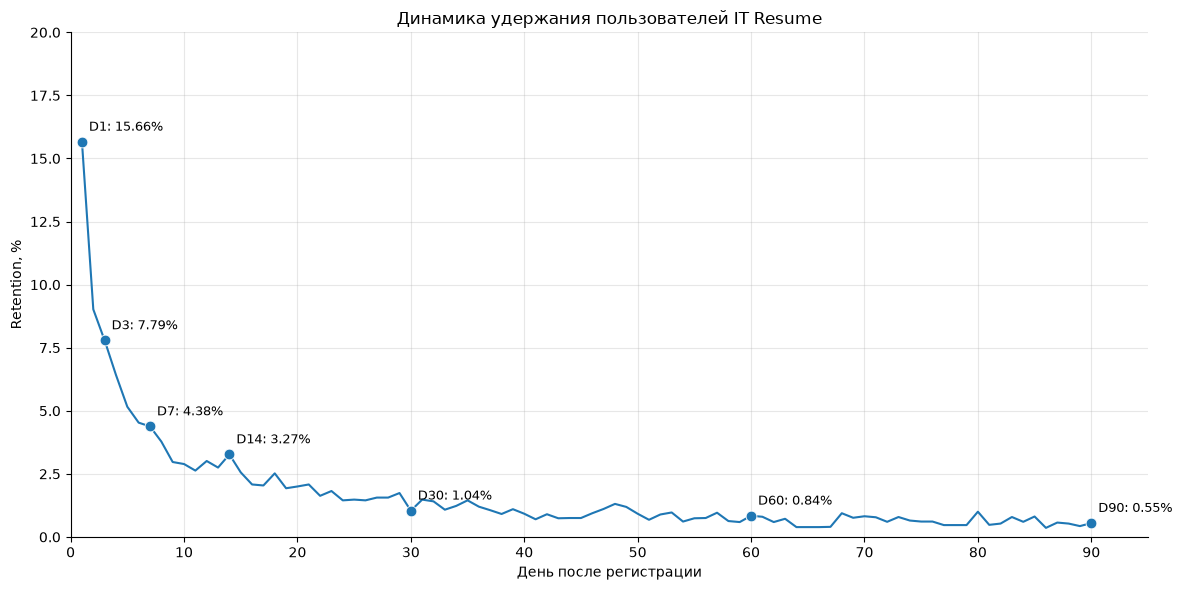

In [29]:
control_days = [1, 3, 7, 14, 30, 60, 90]

# D0 исключаем, чтобы высокая активность в день регистрации не сжимала основную часть retention curve.
df_retention = df_retention_curve[
    df_retention_curve['retention_day'] > 0
]

# Выделяем ключевые дни.
control_points = df_retention[
    df_retention['retention_day'].isin(control_days)
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_retention,
    x='retention_day',
    y='retention_pct'
)

sns.scatterplot(
    data=control_points,
    x='retention_day',
    y='retention_pct',
    s=60,
    zorder=3
)

for _, row in control_points.iterrows():
    plt.annotate(
        f"D{int(row['retention_day'])}: {row['retention_pct']:.2f}%",
        (row['retention_day'], row['retention_pct']),
        xytext=(5, 8),
        textcoords='offset points',
        fontsize=9
    )

plt.title('Динамика удержания пользователей IT Resume')
plt.xlabel('День после регистрации')
plt.ylabel('Retention, %')

plt.xlim(0, 95)
plt.ylim(0, 20)
plt.xticks(range(0, 91, 10))

plt.grid(alpha=0.3)

sns.despine()

plt.tight_layout()

plt.savefig(
    figures_dir / 'retention_curve.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

<a id='rolling-retention'></a>

### 3.2. Rolling retention

N-day retention показывает долю пользователей, вернувшихся на платформу ровно на определённый день после регистрации. При этом пользователь может пропустить этот день и вернуться позже.

Поэтому дополнительно рассчитаем rolling retention — долю пользователей, которые вернулись на платформу в указанный день или в любой последующий день.

Например, Rolling D7 учитывает пользователя как вернувшегося, если у него был хотя бы один вход на D7 или позже.

Для расчёта используем те же контрольные точки D1, D3, D7, D14, D30, D60 и D90. В знаменатель для каждого дня включаем только пользователей, для которых этот день уже наступил к концу периода наблюдения.

In [30]:
%%sql rolling_retention <<

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

last_entries AS (
    SELECT
        bu.user_id,
        bu.registration_date,
        MAX(ue.entry_at::date) AS last_entry_date
    FROM base_users AS bu
    LEFT JOIN userentry AS ue
        ON ue.user_id = bu.user_id
    GROUP BY
        bu.user_id,
        bu.registration_date
),

retention_days AS (
    SELECT GENERATE_SERIES(1, 90) AS retention_day
)

SELECT
    rd.retention_day,
    COUNT(*) AS eligible_users,

    COUNT(*) FILTER (
        WHERE le.last_entry_date
              >= le.registration_date + rd.retention_day
    ) AS retained_users,

    ROUND(
        COUNT(*) FILTER (
            WHERE le.last_entry_date
                  >= le.registration_date + rd.retention_day
        ) * 100.0
        / COUNT(*),
        2
    ) AS rolling_retention_pct

FROM retention_days AS rd
CROSS JOIN last_entries AS le
CROSS JOIN observation AS o

WHERE le.registration_date + rd.retention_day
      <= o.observation_end

GROUP BY rd.retention_day
ORDER BY rd.retention_day;

Преобразуем результат SQL-запроса в DataFrame и сравним rolling retention с рассчитанным ранее N-day retention.

In [31]:
df_rolling_retention = rolling_retention.DataFrame()
df_rolling_retention

,retention_day,eligible_users,retained_users,rolling_retention_pct
0,1,2695,951,35.29
1,2,2695,810,30.06
2,3,2695,751,27.87
3,4,2695,683,25.34
4,5,2695,646,23.97
...,...,...,...,...
85,86,1957,112,5.72
86,87,1923,110,5.72
87,88,1887,107,5.67
88,89,1841,104,5.65


In [32]:
# Оставляем из полной кривой N-day retention те же контрольные дни, для которых рассчитан rolling retention.
control_days = [1, 3, 7, 14, 30, 60, 90]

n_day_control = (
    df_retention_curve[
        df_retention_curve['retention_day'].isin(control_days)
    ][['retention_day', 'retention_pct']]
    .copy()
)

# Объединяем N-day и rolling retention по дню.
retention_comparison = n_day_control.merge(
    df_rolling_retention[
        ['retention_day', 'rolling_retention_pct']
    ],
    on='retention_day'
)

retention_comparison

,retention_day,retention_pct,rolling_retention_pct
0,1,15.66,35.29
1,3,7.79,27.87
2,7,4.38,22.26
3,14,3.27,18.48
4,30,1.04,13.02
5,60,0.84,8.55
6,90,0.55,5.65


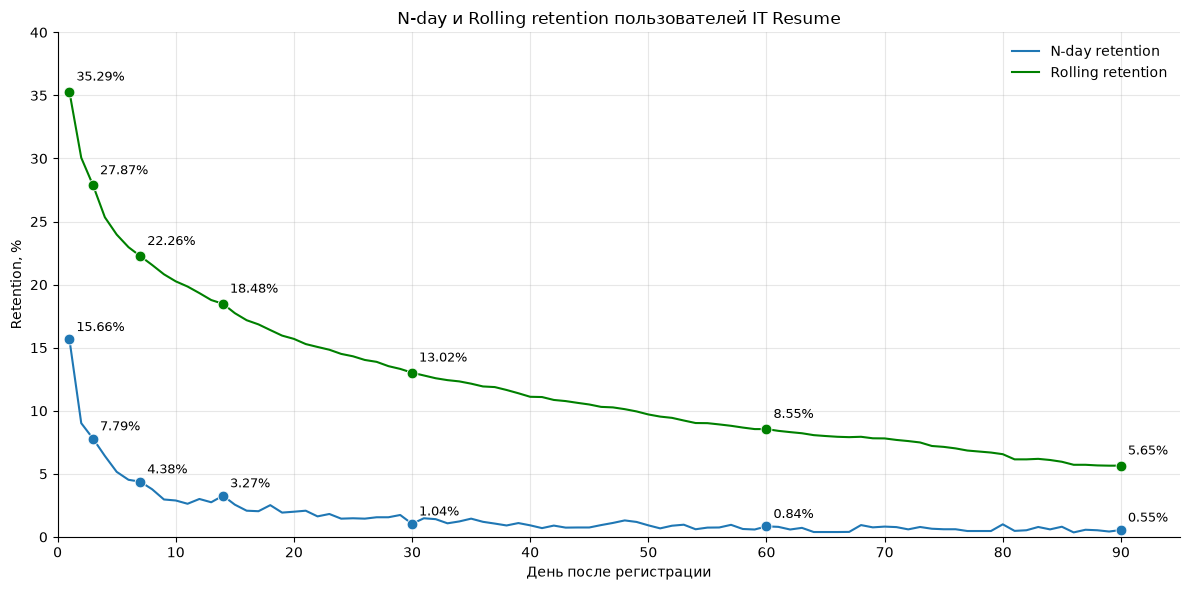

In [33]:
control_days = [1, 3, 7, 14, 30, 60, 90]

# Исключаем D0 из N-day retention.
df_n_day = df_retention_curve[
    df_retention_curve['retention_day'] > 0
].copy()

# Контрольные точки.
n_day_points = df_n_day[
    df_n_day['retention_day'].isin(control_days)
]

rolling_points = df_rolling_retention[
    df_rolling_retention['retention_day'].isin(control_days)
]

plt.figure(figsize=(12, 6))

# Полная кривая N-day retention D1–D90.
sns.lineplot(
    data=df_n_day,
    x='retention_day',
    y='retention_pct',
    label='N-day retention'
)

# Полная кривая Rolling retention D1–D90.
sns.lineplot(
    data=df_rolling_retention,
    x='retention_day',
    y='rolling_retention_pct',
    color='green',
    label='Rolling retention'
)

# Выделяем контрольные точки N-day.
sns.scatterplot(
    data=n_day_points,
    x='retention_day',
    y='retention_pct',
    s=60,
    zorder=3
)

# Выделяем контрольные точки Rolling.
sns.scatterplot(
    data=rolling_points,
    x='retention_day',
    y='rolling_retention_pct',
    color='green',
    s=60,
    zorder=3
)

# Подписи N-day.
for _, row in n_day_points.iterrows():
    plt.annotate(
        f"{row['retention_pct']:.2f}%",
        (row['retention_day'], row['retention_pct']),
        xytext=(5, 6),
        textcoords='offset points',
        fontsize=9
    )

# Подписи Rolling.
for _, row in rolling_points.iterrows():
    plt.annotate(
        f"{row['rolling_retention_pct']:.2f}%",
        (row['retention_day'], row['rolling_retention_pct']),
        xytext=(5, 8),
        textcoords='offset points',
        fontsize=9
    )

plt.title('N-day и Rolling retention пользователей IT Resume')
plt.xlabel('День после регистрации')
plt.ylabel('Retention, %')

plt.xlim(0, 95)
plt.ylim(0, 40)
plt.xticks(range(0, 91, 10))

plt.grid(alpha=0.3)

plt.legend(frameon=False)

sns.despine()

plt.tight_layout()

plt.savefig(
    figures_dir / 'n_day_vs_rolling_retention.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

#### Вывод

Rolling retention заметно выше N-day retention на всех контрольных точках. Например, на D7 N-day retention составляет 4,38%, тогда как Rolling D7 — 22,26%. На D30 показатели составляют 1,04% и 13,02% соответственно.

Это означает, что значительная часть пользователей возвращается на платформу нерегулярно: пользователь может отсутствовать в конкретный контрольный день, но снова воспользоваться платформой позже.

При этом rolling retention также последовательно снижается: с 35,29% на D1 до 22,26% на D7, 13,02% на D30 и 5,65% на D90. Таким образом, вывод о наиболее заметном снижении активности в начале пользовательского пути сохраняется, однако N-day retention сам по себе недооценивает долю пользователей, которые возвращаются на платформу позднее.

[Вернуться к содержанию](#toc)

<a id='cohort-retention'></a>

## 4. Когортный анализ retention

Общий retention показывает выраженное снижение в первые дни после регистрации, но объединяет пользователей, зарегистрированных в разные периоды.

Чтобы проверить, одинаково ли эта динамика проявляется у разных групп пользователей, сравним retention по месячным когортам регистрации.

In [34]:
%%sql cohort_retention <<

-- Рассчитываем retention месячных когорт на контрольных днях.
-- Для каждого дня используем только полностью наблюдаемые когорты.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date,
        DATE_TRUNC('month', date_joined)::date AS cohort_month
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

retention_days AS (
    SELECT retention_day
    FROM (
        VALUES (1), (3), (7), (14), (30), (60), (90)
    ) AS t(retention_day)
),

-- Последняя дата регистрации нужна, чтобы проверить, успела ли вся когорта прожить
-- соответствующее количество дней.
cohort_bounds AS (
    SELECT
        cohort_month,
        MAX(registration_date) AS last_registration_date
    FROM base_users
    GROUP BY cohort_month
)

SELECT
    bu.cohort_month,
    rd.retention_day,
    COUNT(*) AS eligible_users,
    COUNT(e.user_id) AS retained_users,
    ROUND(
        COUNT(e.user_id) * 100.0 / COUNT(*),
        2
    ) AS retention_pct
FROM base_users AS bu
JOIN cohort_bounds AS cb
    ON cb.cohort_month = bu.cohort_month
CROSS JOIN retention_days AS rd
CROSS JOIN observation AS o
LEFT JOIN entries AS e
    ON e.user_id = bu.user_id
    AND e.entry_date = bu.registration_date + rd.retention_day
WHERE cb.last_registration_date + rd.retention_day
      <= o.observation_end
GROUP BY
    bu.cohort_month,
    rd.retention_day
ORDER BY
    bu.cohort_month,
    rd.retention_day;

In [35]:
df_cohort_retention = cohort_retention.DataFrame()
df_cohort_retention

,cohort_month,retention_day,eligible_users,retained_users,retention_pct
0,2021-11-01,1,187,51,27.27
1,2021-11-01,3,187,28,14.97
2,2021-11-01,7,187,18,9.63
3,2021-11-01,14,187,21,11.23
4,2021-11-01,30,187,2,1.07
5,2021-11-01,60,187,8,4.28
6,2021-11-01,90,187,3,1.60
7,2021-12-01,1,132,26,19.70
8,2021-12-01,3,132,11,8.33
9,2021-12-01,7,132,13,9.85


Для наглядного сравнения когорт преобразуем результат SQL-запроса в матрицу: строки будут соответствовать месяцам регистрации, а столбцы — контрольным дням retention.

Размер когорты покажем отдельно, а значения retention выделим оттенками синего: чем выше показатель, тем темнее ячейка. Пустые ячейки означают, что для этой когорты соответствующий горизонт наблюдения ещё недоступен.

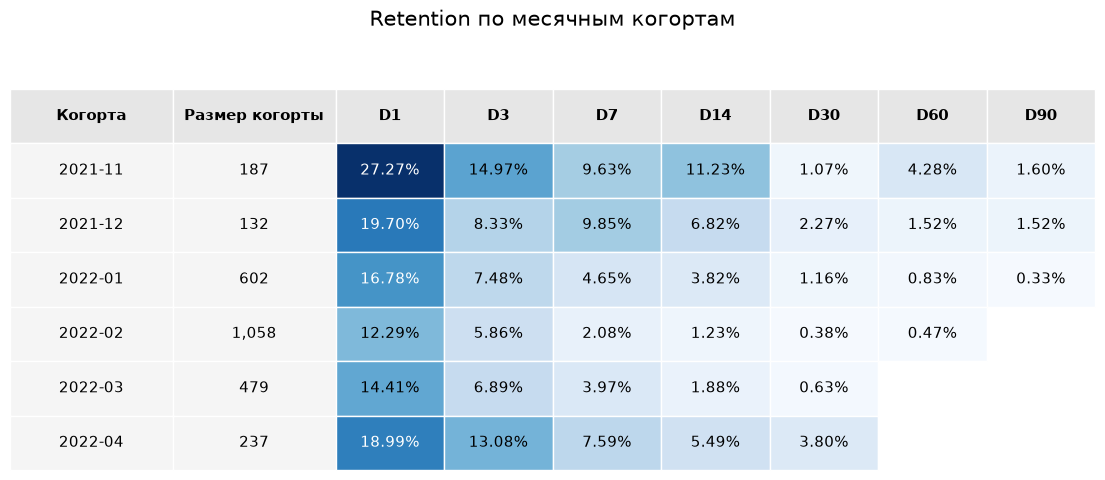

In [36]:
# Приводим retention к числовому типу для дальнейшего форматирования.
df_cohort_retention['retention_pct'] = pd.to_numeric(
    df_cohort_retention['retention_pct']
)

# Месяц регистрации в удобном формате для таблицы.
df_cohort_retention['month'] = (
    pd.to_datetime(df_cohort_retention['cohort_month'])
    .dt.strftime('%Y-%m')
)

# Определяем размер каждой когорты.
cohort_sizes = (
    df_cohort_retention
    .groupby('month', sort=False)['eligible_users']
    .first()
)

# Преобразуем данные из длинного формата в матрицу.
retention_matrix = df_cohort_retention.pivot(
    index='month',
    columns='retention_day',
    values='retention_pct'
)

retention_matrix = retention_matrix.reindex(cohort_sizes.index)

retention_days = [1, 3, 7, 14, 30, 60, 90]
retention_matrix = retention_matrix.reindex(columns=retention_days)

columns = [
    'Когорта',
    'Размер когорты',
    'D1',
    'D3',
    'D7',
    'D14',
    'D30',
    'D60',
    'D90'
]

# Формируем значения, которые будут отображаться в таблице.
table_data = []

for month in retention_matrix.index:
    row = [
        month,
        f'{cohort_sizes[month]:,}'
    ]

    for day in retention_days:
        value = retention_matrix.loc[month, day]

        if pd.isna(value):
            row.append('')
        else:
            row.append(f'{value:.2f}%')

    table_data.append(row)

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.axis('off')

table = ax.table(
    cellText=table_data,
    colLabels=columns,
    cellLoc='center',
    colLoc='center',
    loc='center',
    bbox=[0, 0, 1, 0.9]
)

table.auto_set_font_size(False)
table.set_fontsize(11)

# Ширина столбцов.
column_widths = {
    0: 0.15,
    1: 0.15,
    2: 0.10,
    3: 0.10,
    4: 0.10,
    5: 0.10,
    6: 0.10,
    7: 0.10,
    8: 0.10
}

for (row, col), cell in table.get_celld().items():
    cell.set_width(column_widths[col])
    cell.set_edgecolor('white')

    if row == 0:
        cell.set_text_props(weight='bold')
        cell.set_facecolor('#E6E6E6')

    elif col < 2:
        cell.set_facecolor('#F5F5F5')

# Для retention используем единую цветовую шкалу:
# более высоким значениям соответствует более тёмный оттенок.
cmap = plt.cm.Blues

max_retention = retention_matrix.max().max()

norm = colors.Normalize(
    vmin=0,
    vmax=max_retention
)

for row_idx, month in enumerate(retention_matrix.index, start=1):
    for col_idx, day in enumerate(retention_days, start=2):
        value = retention_matrix.loc[month, day]
        cell = table[row_idx, col_idx]

        # Пустая ячейка означает, что этот день
        # для когорты ещё недоступен.
        if pd.isna(value):
            cell.set_facecolor('white')
            continue

        cell.set_facecolor(cmap(norm(value)))

        # Цвет текста.
        if norm(value) > 0.55:
            cell.get_text().set_color('white')
        else:
            cell.get_text().set_color('black')

plt.title(
    'Retention по месячным когортам',
    fontsize=15,
    pad=15
)

plt.savefig(
    figures_dir / 'cohort_retention_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

#### Вывод

Когортный анализ показывает заметные различия в retention пользователей в зависимости от месяца регистрации.

С ноября по февраль D1 retention последовательно снижается с 27,27% до 12,29%. Февральская когорта при этом является самой крупной — 1 058 пользователей — и показывает наиболее низкие значения retention на большинстве контрольных дней: D7 — 2,08%, D14 — 1,23%, D30 — 0,38%.

В марте показатели начинают расти, а в апрельской когорте D1 retention составляет уже 18,99%, D7 — 7,59%, D14 — 5,49%, D30 — 3,80%.

Таким образом, снижение retention не было одинаковым для всех когорт: после ухудшения показателей к февралю в марте и апреле наблюдается рост. Однако по имеющимся данным нельзя определить причины этих изменений только по месяцу регистрации. Поэтому далее проверим, какие особенности поведения пользователей в первые дни связаны с последующим удержанием.

Для поздних когорт D60 и D90 не рассчитываются, если соответствующий период после регистрации ещё не прошёл для всей когорты.

[Вернуться к содержанию](#toc)

<a id='hypotheses'></a>

## 5. Проверка гипотез

После анализа общей динамики и месячных когорт проверим, какие особенности поведения пользователей в первые дни после регистрации связаны с D7 retention.

<a id='h1'></a>

### 5.1. H1. Количество активных дней в D0–D2 и последующий retention

**Гипотеза H1:** чем больше дней пользователь активен в период D0–D2, тем выше его D7 retention.

В качестве показателя ранней активности используем количество дней, в которые у пользователя был зафиксирован вход на платформу в первые три календарных дня, включая день регистрации.

Разделим пользователей на группы по количеству активных дней в D0–D2 и сравним их D7 retention. Дополнительно посмотрим D30 retention, чтобы проверить, сохраняется ли такая же тенденция на более длинном периоде.

Для всех пользователей выборки к концу периода наблюдения уже наступил D30, поэтому D7 и D30 рассчитываются на одной и той же выборке.

In [37]:
%%sql early_activity_retention <<

-- Сравниваем D7 и D30 retention в зависимости от количества активных дней пользователя в D0–D2.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

-- Считаем количество активных дней в первые три дня.
early_activity AS (
    SELECT
        bu.user_id,
        bu.registration_date,
        COUNT(
            DISTINCT CASE
                WHEN e.entry_date BETWEEN bu.registration_date
                                      AND bu.registration_date + 2
                THEN e.entry_date
            END
        ) AS early_active_days
    FROM base_users AS bu
    LEFT JOIN entries AS e
        ON e.user_id = bu.user_id
    GROUP BY
        bu.user_id,
        bu.registration_date
),

-- Определяем возвращение пользователя на D7 и D30.
user_retention AS (
    SELECT
        ea.user_id,
        ea.registration_date,
        ea.early_active_days,

        MAX(
            CASE
                WHEN e.entry_date = ea.registration_date + 7
                THEN 1 ELSE 0
            END
        ) AS retained_d7,

        MAX(
            CASE
                WHEN e.entry_date = ea.registration_date + 30
                THEN 1 ELSE 0
            END
        ) AS retained_d30

    FROM early_activity AS ea
    LEFT JOIN entries AS e
        ON e.user_id = ea.user_id
    GROUP BY
        ea.user_id,
        ea.registration_date,
        ea.early_active_days
)

SELECT
    ur.early_active_days,
    COUNT(*) AS users,

    SUM(ur.retained_d7) AS retained_d7,
    ROUND(
        AVG(ur.retained_d7) * 100,
        2
    ) AS d7_retention_pct,

    SUM(ur.retained_d30) AS retained_d30,
    ROUND(
        AVG(ur.retained_d30) * 100,
        2
    ) AS d30_retention_pct

FROM user_retention AS ur
CROSS JOIN observation AS o

-- Для всех пользователей должен быть доступен D30.
WHERE ur.registration_date + 30 <= o.observation_end

GROUP BY ur.early_active_days
ORDER BY ur.early_active_days;

In [38]:
df_early_activity = early_activity_retention.DataFrame()
df_early_activity

,early_active_days,users,retained_d7,d7_retention_pct,retained_d30,d30_retention_pct
0,0,414,3,0.72,2,0.48
1,1,1772,35,1.98,5,0.28
2,2,374,38,10.16,11,2.94
3,3,135,42,31.11,10,7.41


Для сравнения групп построим график D7 и D30 retention в зависимости от количества активных дней в D0–D2. D7 используем как основной показатель для проверки гипотезы, а D30 — как дополнительный показатель более долгосрочного удержания.

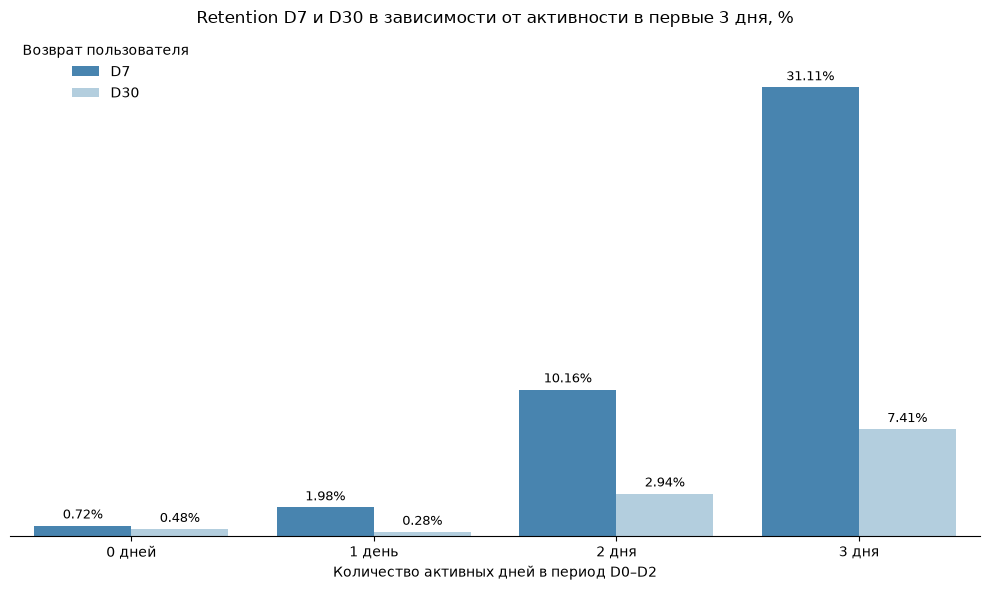

In [39]:
# Приводим значения retention к числовому типу.
df_early_activity['d7_retention_pct'] = pd.to_numeric(
    df_early_activity['d7_retention_pct']
)

df_early_activity['d30_retention_pct'] = pd.to_numeric(
    df_early_activity['d30_retention_pct']
)

# Переводим данные в удобный формат для группировки D7 и D30.
df_early_plot = df_early_activity.melt(
    id_vars=['early_active_days'],
    value_vars=['d7_retention_pct', 'd30_retention_pct'],
    var_name='retention_period',
    value_name='retention_pct'
)

df_early_plot['retention_period'] = (
    df_early_plot['retention_period']
    .replace({
        'd7_retention_pct': 'D7',
        'd30_retention_pct': 'D30'
    })
)

activity_labels = {
    0: '0 дней',
    1: '1 день',
    2: '2 дня',
    3: '3 дня'
}

df_early_plot['activity_group'] = (
    df_early_plot['early_active_days']
    .map(activity_labels)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=df_early_plot,
    x='activity_group',
    y='retention_pct',
    hue='retention_period',
    palette='Blues_r'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=3,
        fontsize=9
    )

ax.set_yticks([])
plt.title('Retention D7 и D30 в зависимости от активности в первые 3 дня, %')
plt.xlabel('Количество активных дней в период D0–D2')
plt.ylabel('')
plt.legend(title='Возврат пользователя', frameon=False)

plt.ylim(0, 35)
plt.tight_layout()
sns.despine(left=True)

plt.savefig(
    figures_dir / 'early_activity_retention.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

#### Статистическая проверка H1

Чтобы проверить, связаны ли количество активных дней в D0–D2 и удержание на D7, используем критерий χ² Пирсона.

Обе переменные категориальные: пользователи разделены по количеству активных дней (0, 1, 2 или 3), а D7 retention принимает два значения — пользователь вернулся или не вернулся.

Критерий χ² позволяет определить наличие статистически значимой связи, но не показывает, насколько она выражена. Поэтому дополнительно рассчитаем коэффициент Cramér's V, который используется для оценки силы связи между категориальными признаками. Чем ближе его значение к 0, тем слабее связь; чем ближе к 1 — тем сильнее.

- **H₀:** количество активных дней в D0–D2 и возвращение на D7 не связаны.
- **H₁:** между количеством активных дней в D0–D2 и возвращением на D7 существует статистически значимая связь.

Уровень значимости: α = 0,05.

In [40]:
# Формируем таблицу: для каждой группы активности и считаем вернувшихся и не вернувшихся на D7.
contingency_d7 = pd.DataFrame({
    'retained': df_early_activity['retained_d7'],
    'not_retained': (
        df_early_activity['users']
        - df_early_activity['retained_d7']
    )
})

# Проверяем связь с помощью критерия χ² Пирсона.
chi2_d7, p_d7, dof_d7, expected_freq_d7 = chi2_contingency(
    contingency_d7
)

# Рассчитываем Cramér's V для оценки силы связи.
n = df_early_activity['users'].sum()
cramers_v_d7 = (chi2_d7 / n) ** 0.5

alpha = 0.05

print(f'χ² = {chi2_d7:.2f}')
print(f'p-value = {p_d7:.4g}')
print(f"Cramér's V = {cramers_v_d7:.3f}")
print(
    f'Минимальная ожидаемая частота = '
    f'{expected_freq_d7.min():.2f}'
)

if p_d7 < alpha:
    print(
        'Результат: H₀ отвергается. '
        'Обнаружена статистически значимая связь '
        'между количеством активных дней в D0–D2 и D7 retention.'
    )
else:
    print(
        'Результат: нет оснований отвергнуть H₀. '
        'Статистически значимая связь не обнаружена.'
    )

χ² = 297.94
p-value = 2.777e-64
Cramér's V = 0.332
Минимальная ожидаемая частота = 5.91
Результат: H₀ отвергается. Обнаружена статистически значимая связь между количеством активных дней в D0–D2 и D7 retention.


#### Вывод по H1

D7 retention последовательно растёт с увеличением количества активных дней в D0–D2: с 0,72% среди пользователей без зафиксированной активности до 31,11% среди пользователей, активных во все три дня.

Связь между количеством активных дней в D0–D2 и возвращением на D7 статистически значима (χ² = 297,94; p < 0,001). Cramér's V = 0,332 указывает на заметную связь между признаками.

На D30 похожая картина наблюдается прежде всего среди пользователей, активных два и три дня: retention в этих группах составляет 2,94% и 7,41% соответственно. D30 используется здесь как дополнительный показатель и отдельно статистически не проверяется.

Таким образом, H1 поддерживается данными: более регулярная активность в первые дни после регистрации связана с более высоким D7 retention. При этом результат показывает связь, но не доказывает, что именно ранняя активность является причиной более высокого удержания.

<a id='h2'></a>

### 5.2. H2. Начало работы с задачами в первые три дня и D7 retention

**Гипотеза H2:**  начало работы с задачами в первые три дня связано с более высоким D7 retention.

Рассмотрим два действия пользователя в период D0–D2:

- `CodeRun` — пользователь запускал код при работе над задачей;
- `CodeSubmit` — пользователь отправлял решение на проверку.

Для каждого действия сравним D7 retention пользователей, которые совершали его в первые три дня после регистрации, с пользователями, у которых такого действия не было.

#### Запуск CodeRun в перые три дня

Сначала проверим, связан ли хотя бы один запуск кода в D0–D2 с последующим возвращением пользователя на D7.

In [41]:
%%sql early_coderun_retention <<

-- Сравниваем D7 retention пользователей с запуском CodeRun в первые три дня и без него.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

-- Определяем наличие CodeRun в D0–D2.
early_coderun AS (
    SELECT
        bu.user_id,
        bu.registration_date,
        CASE
            WHEN EXISTS (
                SELECT 1
                FROM coderun AS cr
                WHERE cr.user_id = bu.user_id
                  AND cr.created_at::date
                      BETWEEN bu.registration_date
                          AND bu.registration_date + 2
            )
            THEN 1
            ELSE 0
        END AS has_early_coderun
    FROM base_users AS bu
),

-- Определяем возвращение пользователя на D7.
user_retention AS (
    SELECT
        ec.user_id,
        ec.registration_date,
        ec.has_early_coderun,
        CASE
            WHEN EXISTS (
                SELECT 1
                FROM entries AS e
                WHERE e.user_id = ec.user_id
                  AND e.entry_date = ec.registration_date + 7
            )
            THEN 1
            ELSE 0
        END AS retained_d7
    FROM early_coderun AS ec
)

SELECT
    ur.has_early_coderun,
    COUNT(*) AS users,
    SUM(ur.retained_d7) AS retained_d7,
    ROUND(
        AVG(ur.retained_d7) * 100,
        2
    ) AS d7_retention_pct
FROM user_retention AS ur
CROSS JOIN observation AS o
WHERE ur.registration_date + 7 <= o.observation_end
GROUP BY ur.has_early_coderun
ORDER BY ur.has_early_coderun;

Преобразуем результат в DataFrame для статистической проверки и дальнейшей визуализации.

In [42]:
df_early_coderun = early_coderun_retention.DataFrame()
df_early_coderun

,has_early_coderun,users,retained_d7,d7_retention_pct
0,0,1977,38,1.92
1,1,718,80,11.14


Проверим, является ли связь между ранним CodeRun и D7 retention статистически значимой. Как и в предыдущей гипотезе, используем критерий χ² Пирсона и Cramér's V для оценки силы связи.

- **H₀:** запуск CodeRun в первые три дня и возвращение на D7 не связаны.
- **H₁:** между запуском CodeRun в первые три дня и возвращением на D7 существует статистически значимая связь.

Уровень значимости: α = 0,05.

In [43]:
contingency_coderun = pd.DataFrame({
    'retained': df_early_coderun['retained_d7'],
    'not_retained': (
        df_early_coderun['users']
        - df_early_coderun['retained_d7']
    )
})

chi2_run, p_run, dof_run, expected_freq_run = chi2_contingency(
    contingency_coderun
)

n = df_early_coderun['users'].sum()
cramers_v_run = (chi2_run / n) ** 0.5

alpha = 0.05

print(f'χ² = {chi2_run:.2f}')
print(f'p-value = {p_run:.4g}')
print(f"Cramér's V = {cramers_v_run:.3f}")
print(
    f'Минимальная ожидаемая частота = '
    f'{expected_freq_run.min():.2f}'
)

if p_run < alpha:
    print(
        'Результат: H₀ отвергается. '
        'Обнаружена статистически значимая связь '
        'между запуском CodeRun в первые три дня и D7 retention.'
    )
else:
    print(
        'Результат: нет оснований отвергнуть H₀. '
        'Статистически значимая связь не обнаружена.'
    )

χ² = 104.75
p-value = 1.384e-24
Cramér's V = 0.197
Минимальная ожидаемая частота = 31.44
Результат: H₀ отвергается. Обнаружена статистически значимая связь между запуском CodeRun в первые три дня и D7 retention.


D7 retention пользователей с запуском CodeRun в первые три дня составляет 11,14% против 1,92% среди пользователей без CodeRun. Различия статистически значимы (χ² = 104,75; p < 0,001), Cramér's V = 0,197.

#### Запуск CodeSubmit в первые три дня

Теперь проверим, связан ли хотя бы один CodeSubmit в D0–D2 с последующим возвращением пользователя на D7.

In [44]:
%%sql early_codesubmit_retention <<

-- Сравниваем D7 retention пользователей с запуском CodeSubmit в первые три дня и без него.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

-- Определяем наличие CodeSubmit в D0–D2.
early_codesubmit AS (
    SELECT
        bu.user_id,
        bu.registration_date,
        CASE
            WHEN EXISTS (
                SELECT 1
                FROM codesubmit AS cs
                WHERE cs.user_id = bu.user_id
                  AND cs.created_at::date
                      BETWEEN bu.registration_date
                          AND bu.registration_date + 2
            )
            THEN 1
            ELSE 0
        END AS has_early_codesubmit
    FROM base_users AS bu
),

-- Определяем возвращение пользователя на D7.
user_retention AS (
    SELECT
        ecs.user_id,
        ecs.registration_date,
        ecs.has_early_codesubmit,
        CASE
            WHEN EXISTS (
                SELECT 1
                FROM entries AS e
                WHERE e.user_id = ecs.user_id
                  AND e.entry_date = ecs.registration_date + 7
            )
            THEN 1
            ELSE 0
        END AS retained_d7
    FROM early_codesubmit AS ecs
)

SELECT
    ur.has_early_codesubmit,
    COUNT(*) AS users,
    SUM(ur.retained_d7) AS retained_d7,
    ROUND(
        AVG(ur.retained_d7) * 100,
        2
    ) AS d7_retention_pct
FROM user_retention AS ur
CROSS JOIN observation AS o
WHERE ur.registration_date + 7 <= o.observation_end
GROUP BY ur.has_early_codesubmit
ORDER BY ur.has_early_codesubmit;

Преобразуем результат в DataFrame для статистической проверки и дальнейшей визуализации.

In [45]:
df_early_codesubmit = early_codesubmit_retention.DataFrame()
df_early_codesubmit

,has_early_codesubmit,users,retained_d7,d7_retention_pct
0,0,1991,41,2.06
1,1,704,77,10.94


Проверим статистическую значимость связи между запуском CodeSubmit в первые три дня и D7 retention тем же способом.

- **H₀:** запуск CodeSubmit в первые три дня и возвращение на D7 не связаны.
- **H₁:** между запуском CodeSubmit в первые три дня и возвращением на D7 существует статистически значимая связь.

Уровень значимости: α = 0,05.

In [46]:
contingency_codesubmit = pd.DataFrame({
    'retained': df_early_codesubmit['retained_d7'],
    'not_retained': (
        df_early_codesubmit['users']
        - df_early_codesubmit['retained_d7']
    )
})

chi2_submit, p_submit, dof_submit, expected_freq_submit = chi2_contingency(
    contingency_codesubmit
)

n = df_early_codesubmit['users'].sum()
cramers_v_submit = (chi2_submit / n) ** 0.5

alpha = 0.05

print(f'χ² = {chi2_submit:.2f}')
print(f'p-value = {p_submit:.4g}')
print(f"Cramér's V = {cramers_v_submit:.3f}")
print(
    f'Минимальная ожидаемая частота = '
    f'{expected_freq_submit.min():.2f}'
)

if p_submit < alpha:
    print(
        'Результат: H₀ отвергается. '
        'Обнаружена статистически значимая связь '
        'между запуском CodeSubmit в первые три дня  и D7 retention.'
    )
else:
    print(
        'Результат: нет оснований отвергнуть H₀. '
        'Статистически значимая связь не обнаружена.'
    )

χ² = 95.81
p-value = 1.266e-22
Cramér's V = 0.189
Минимальная ожидаемая частота = 30.82
Результат: H₀ отвергается. Обнаружена статистически значимая связь между запуском CodeSubmit в первые три дня  и D7 retention.


D7 retention пользователей с запуском CodeSubmit в первые три дня составляет 10,94% против 2,06% среди пользователей без CodeSubmit. Различия статистически значимы (χ² = 95,81; p < 0,001), Cramér's V = 0,189.

#### Вывод по H2

Работа с задачами в первые три дня связана с более высоким D7 retention.

Среди пользователей с CodeRun в D0–D2 D7 retention составляет 11,14% против 1,92% среди пользователей без запуска CodeRun в первые три дня. Для CodeSubmit значения составляют 10,94% и 2,06% соответственно.

В обоих случаях связь с D7 retention статистически значима (p < 0,001). Cramér's V составляет 0,197 для CodeRun и 0,189 для CodeSubmit.

Таким образом, H2 поддерживается данными: пользователи, которые начинают работать с задачами в первые дни после регистрации, чаще возвращаются на платформу на D7. При этом результаты показывают связь, но не доказывают причинное влияние работы с задачами на удержание.

<a id='h3'></a>

### 5.3. H3. Первое успешное решение в первые три дня и D7 retention

**Гипотеза H3:** получение успешного решения в D0–D2 связано с более высоким D7 retention.

Успешным решением считаем CodeSubmit с `is_false = 0`. Разделим пользователей на две группы в зависимости от того, было ли у них хотя бы одно успешное решение в первые три дня после регистрации, и сравним их D7 retention.

In [47]:
%%sql early_success_retention <<

-- Сравниваем D7 retention пользователей с успешным решением в D0–D2 и без него.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

-- Определяем наличие успешного CodeSubmit в D0–D2.
early_success AS (
    SELECT
        bu.user_id,
        bu.registration_date,
        CASE
            WHEN EXISTS (
                SELECT 1
                FROM codesubmit AS cs
                WHERE cs.user_id = bu.user_id
                  AND cs.is_false = 0
                  AND cs.created_at::date
                      BETWEEN bu.registration_date
                          AND bu.registration_date + 2
            )
            THEN 1
            ELSE 0
        END AS has_early_success
    FROM base_users AS bu
),

-- Определяем возвращение пользователя на D7.
user_retention AS (
    SELECT
        es.user_id,
        es.registration_date,
        es.has_early_success,
        CASE
            WHEN EXISTS (
                SELECT 1
                FROM entries AS e
                WHERE e.user_id = es.user_id
                  AND e.entry_date = es.registration_date + 7
            )
            THEN 1
            ELSE 0
        END AS retained_d7
    FROM early_success AS es
)

SELECT
    ur.has_early_success,
    COUNT(*) AS users,
    SUM(ur.retained_d7) AS retained_d7,
    ROUND(
        AVG(ur.retained_d7) * 100,
        2
    ) AS d7_retention_pct
FROM user_retention AS ur
CROSS JOIN observation AS o
WHERE ur.registration_date + 7 <= o.observation_end
GROUP BY ur.has_early_success
ORDER BY ur.has_early_success;

Преобразуем результат в DataFrame для статистической проверки и визуализации.

In [48]:
df_early_success = early_success_retention.DataFrame()
df_early_success

,has_early_success,users,retained_d7,d7_retention_pct
0,0,2120,43,2.03
1,1,575,75,13.04


#### Статистическая проверка H3

Проверим статистическую значимость связи между первым успешным решением в первые три дня и D7 retention с помощью критерия χ² Пирсона. Для оценки силы связи дополнительно рассчитаем Cramér's V.

- **H₀:** первое успешное решение в первые три дня и возвращение на D7 не связаны.
- **H₁:** между первым успешным решением в первые три дня и возвращением на D7 существует статистически значимая связь.

Уровень значимости: α = 0,05.

In [49]:
contingency_success = pd.DataFrame({
    'retained': df_early_success['retained_d7'],
    'not_retained': (
        df_early_success['users']
        - df_early_success['retained_d7']
    )
})

chi2_success, p_success, dof_success, expected_freq_success = chi2_contingency(
    contingency_success
)

n = df_early_success['users'].sum()
cramers_v_success = (chi2_success / n) ** 0.5

alpha = 0.05

print(f'χ² = {chi2_success:.2f}')
print(f'p-value = {p_success:.4g}')
print(f"Cramér's V = {cramers_v_success:.3f}")
print(
    f'Минимальная ожидаемая частота = '
    f'{expected_freq_success.min():.2f}'
)

if p_success < alpha:
    print(
        'Результат: H₀ отвергается. '
        'Обнаружена статистически значимая связь '
        'между первым успешным решением в первые три дня и D7 retention.'
    )
else:
    print(
        'Результат: нет оснований отвергнуть H₀. '
        'Статистически значимая связь не обнаружена.'
    )

χ² = 128.47
p-value = 8.875e-30
Cramér's V = 0.218
Минимальная ожидаемая частота = 25.18
Результат: H₀ отвергается. Обнаружена статистически значимая связь между первым успешным решением в первые три дня и D7 retention.


Сравним результаты трёх последовательных этапов  работы с задачами в первые три дня: запуска кода, отправки решения и получения успешного решения.

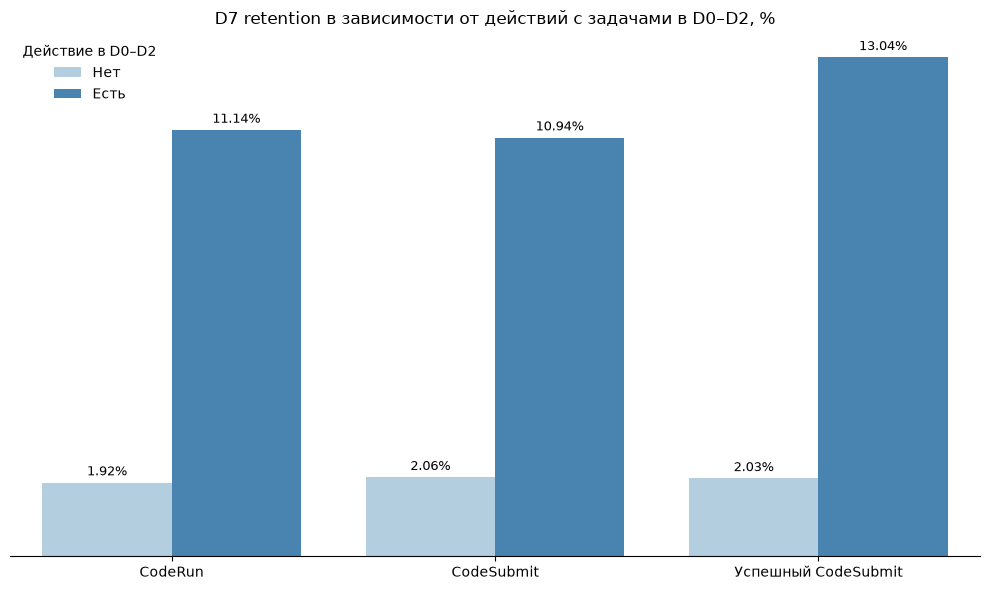

In [50]:
task_retention = pd.DataFrame({
    'Действие': [
        'CodeRun', 'CodeRun',
        'CodeSubmit', 'CodeSubmit',
        'Успешный CodeSubmit', 'Успешный CodeSubmit'
    ],
    'Группа': [
        'Нет', 'Есть',
        'Нет', 'Есть',
        'Нет', 'Есть'
    ],
    'D7 retention': [
        *pd.to_numeric(df_early_coderun['d7_retention_pct']),
        *pd.to_numeric(df_early_codesubmit['d7_retention_pct']),
        *pd.to_numeric(df_early_success['d7_retention_pct'])
    ]
})

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=task_retention,
    x='Действие',
    y='D7 retention',
    hue='Группа',
    palette='Blues'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=3,
        fontsize=9
    )

plt.title(
    'D7 retention в зависимости от действий с задачами в D0–D2, %'
)
plt.xlabel('')
plt.ylabel('')
plt.yticks([])

sns.despine(left=True)

plt.legend(
    title='Действие в D0–D2',
    frameon=False
)

plt.tight_layout()

plt.savefig(
    figures_dir / 'early_task_actions_retention.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

#### Вывод по H3

Пользователи, получившие хотя бы одно успешное решение в D0–D2, возвращаются на D7 заметно чаще: D7 retention составляет 13,04% против 2,03% среди пользователей без первого успешного решения в первые три дня.

Связь статистически значима (χ² = 128,47; p < 0,001), Cramér's V = 0,218.

Таким образом, H3 поддерживается данными: получение успешного решения в первые три дня связано с более высоким D7 retention. При этом результат показывает связь, но не доказывает, что именно успешное решение является причиной последующего возвращения пользователя.

<a id='h4'></a>

### 5.4. H4. Неуспешные попытки до первого успеха и D7 retention

**Гипотеза H4:** большое количество неуспешных попыток до первого успешного решения связано с более низким D7 retention.

Для проверки гипотезы рассмотрим пользователей, которые получили первое успешное решение в D0–D2. Для каждого пользователя посчитаем количество неуспешных CodeSubmit до первого успешного решения и сравним этот показатель между пользователями, вернувшимися и не вернувшимися на D7.

In [51]:
%%sql failed_before_success <<

-- Для пользователей с первым успешным решением в D0–D2 считаем количество неуспешных попыток
-- до первого успеха.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

-- Находим первое успешное решение каждого пользователя.
first_success AS (
    SELECT
        bu.user_id,
        bu.registration_date,
        MIN(cs.created_at) AS first_success_at
    FROM base_users AS bu
    JOIN codesubmit AS cs
        ON cs.user_id = bu.user_id
       AND cs.is_false = 0
    GROUP BY
        bu.user_id,
        bu.registration_date
),

-- Оставляем пользователей, получивших первый успех в D0–D2.
early_first_success AS (
    SELECT
        user_id,
        registration_date,
        first_success_at
    FROM first_success
    WHERE first_success_at::date
          BETWEEN registration_date AND registration_date + 2
),

-- Считаем неуспешные попытки до первого успешного решения.
user_attempts AS (
    SELECT
        efs.user_id,
        efs.registration_date,
        efs.first_success_at,
        COUNT(cs.id) AS failed_before_success
    FROM early_first_success AS efs
    LEFT JOIN codesubmit AS cs
        ON cs.user_id = efs.user_id
       AND cs.is_false = 1
       AND cs.created_at < efs.first_success_at
    GROUP BY
        efs.user_id,
        efs.registration_date,
        efs.first_success_at
)

SELECT
    ua.user_id,
    ua.failed_before_success,
    CASE
        WHEN EXISTS (
            SELECT 1
            FROM entries AS e
            WHERE e.user_id = ua.user_id
              AND e.entry_date = ua.registration_date + 7
        )
        THEN 1
        ELSE 0
    END AS retained_d7
FROM user_attempts AS ua
CROSS JOIN observation AS o
WHERE ua.registration_date + 7 <= o.observation_end
ORDER BY
    ua.failed_before_success,
    ua.user_id;

Преобразуем результат в DataFrame и посмотрим на распределение количества неуспешных попыток.

In [52]:
df_failed_before_success = failed_before_success.DataFrame()
df_failed_before_success 

,user_id,failed_before_success,retained_d7
0,106,0,0
1,114,0,0
2,138,0,0
3,140,0,1
4,147,0,0
...,...,...,...
570,311,24,1
571,600,26,0
572,427,28,1
573,1757,37,0


Сначала посмотрим на распределение количества неуспешных попыток до первого успеха.

In [53]:
df_failed_before_success['failed_before_success'].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
)

count    575.000000
mean       2.269565
std        3.948540
min        0.000000
25%        0.000000
50%        1.000000
75%        3.000000
90%        6.000000
95%        9.000000
max       43.000000
Name: failed_before_success, dtype: float64

Теперь сравним количество неуспешных попыток между пользователями, которые вернулись на D7, и теми, кто не вернулся.

In [54]:
failed_stats = (
    df_failed_before_success
    .groupby('retained_d7')['failed_before_success']
    .agg(
        users='count',
        median='median',
        mean='mean',
        max='max'
    )
    .round(2)
)

failed_stats

,users,median,mean,max
retained_d7,,,,
0,500,1.0,2.06,37
1,75,1.0,3.68,43


#### Статистическая проверка H4

Количество неуспешных попыток — числовой дискретный показатель. Его распределение заметно скошено: у большинства пользователей попыток немного, но встречаются отдельные значения до 43. Поэтому для сравнения двух независимых групп используем непараметрический критерий Манна — Уитни, который не требует нормального распределения данных.

Сравниваем пользователей, которые вернулись на D7, с пользователями, которые не вернулись.

- **H₀:** распределение количества неуспешных попыток до первого успеха не различается между группами.
- **H₁:** распределение количества неуспешных попыток до первого успеха различается между группами.

Уровень значимости: α = 0,05.

In [55]:
# Разделяем пользователей на две независимые группы.
failed_retained = df_failed_before_success.loc[
    df_failed_before_success['retained_d7'] == 1,
    'failed_before_success'
]

failed_not_retained = df_failed_before_success.loc[
    df_failed_before_success['retained_d7'] == 0,
    'failed_before_success'
]

# Сравниваем распределения количества неуспешных попыток.
u_stat, p_mw = mannwhitneyu(
    failed_retained,
    failed_not_retained,
    alternative='two-sided'
)

alpha = 0.05

print(f'U = {u_stat:.0f}')
print(f'p-value = {p_mw:.4g}')

if p_mw < alpha:
    print(
        'Результат: H₀ отвергается. '
        'Распределение количества неуспешных попыток '
        'различается между группами D7 retention.'
    )
else:
    print(
        'Результат: нет оснований отвергнуть H₀. '
        'Статистически значимых различий между группами не обнаружено.'
    )

U = 19947
p-value = 0.3581
Результат: нет оснований отвергнуть H₀. Статистически значимых различий между группами не обнаружено.


#### Вывод по H4

Медианное количество неуспешных попыток до первого успешного решения одинаково в обеих группах и составляет 1 попытку. При этом среднее значение среди пользователей, вернувшихся на D7, даже выше: 3,68 против 2,06.

Критерий Манна — Уитни не выявил статистически значимых различий между группами (U = 19 947; p = 0,358).

Таким образом, H4 не поддерживается данными: среди пользователей, получивших первый успех в D0–D2, нет оснований утверждать, что большее количество неуспешных попыток до первого успеха связано с более низким D7 retention.

<a id='h5'></a>

### 5.5. H5. Сложность первой задачи и D7 retention

**Гипотеза H5:** более высокая сложность первой задачи связана с более низким D7 retention.

В таблице `problem` сложность задачи задана значениями от 1 до 3. В качестве первой задачи пользователя будем считать задачу, для которой был зафиксирован его первый CodeRun в период D0–D2.

Сначала посмотрим, сколько задач относится к каждому уровню сложности в таблице `problem`.

In [56]:
%%sql

SELECT
    complexity,
    COUNT(*) AS problems
FROM problem
GROUP BY complexity
ORDER BY complexity;

complexity,problems
1,172
2,65
3,11


In [57]:
%%sql first_problem_complexity_retention <<

-- Определяем первую задачу пользователя в D0–D2 и сравниваем D7 retention по уровням её сложности.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

-- Находим первый CodeRun пользователя в D0–D2.
first_run AS (
    SELECT DISTINCT ON (cr.user_id)
        cr.user_id,
        bu.registration_date,
        cr.problem_id,
        cr.created_at AS first_run_at
    FROM coderun AS cr
    JOIN base_users AS bu
        ON bu.user_id = cr.user_id
    WHERE cr.created_at::date
          BETWEEN bu.registration_date
              AND bu.registration_date + 2
    ORDER BY
        cr.user_id,
        cr.created_at
),

user_data AS (
    SELECT
        fr.user_id,
        fr.registration_date,
        p.complexity,
        CASE
            WHEN EXISTS (
                SELECT 1
                FROM entries AS e
                WHERE e.user_id = fr.user_id
                  AND e.entry_date = fr.registration_date + 7
            )
            THEN 1
            ELSE 0
        END AS retained_d7
    FROM first_run AS fr
    JOIN problem AS p
        ON p.id = fr.problem_id
)

SELECT
    ud.complexity,
    COUNT(*) AS users,
    SUM(ud.retained_d7) AS retained_d7,
    ROUND(
        AVG(ud.retained_d7) * 100,
        2
    ) AS d7_retention_pct
FROM user_data AS ud
CROSS JOIN observation AS o
WHERE ud.registration_date + 7 <= o.observation_end
GROUP BY ud.complexity
ORDER BY ud.complexity;

In [58]:
df_first_problem_complexity_retention = first_problem_complexity_retention.DataFrame()
df_first_problem_complexity_retention

,complexity,users,retained_d7,d7_retention_pct
0,1,611,69,11.29
1,2,68,8,11.76
2,3,39,3,7.69


Для статистической проверки сформируем данные на уровне пользователя: для каждого пользователя сохраним сложность его первой задачи и признак возвращения на D7.

In [59]:
%%sql first_problem_complexity_users <<

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT MAX(ue.entry_at::date) AS observation_end
    FROM userentry ue
    JOIN base_users bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry ue
    JOIN base_users bu
        ON bu.user_id = ue.user_id
),

first_run AS (
    SELECT DISTINCT ON (cr.user_id)
        cr.user_id,
        bu.registration_date,
        cr.problem_id
    FROM coderun cr
    JOIN base_users bu
        ON bu.user_id = cr.user_id
    WHERE cr.created_at::date
          BETWEEN bu.registration_date AND bu.registration_date + 2
    ORDER BY
        cr.user_id,
        cr.created_at
)

SELECT
    fr.user_id,
    p.complexity,
    CASE
        WHEN EXISTS (
            SELECT 1
            FROM entries e
            WHERE e.user_id = fr.user_id
              AND e.entry_date = fr.registration_date + 7
        )
        THEN 1
        ELSE 0
    END AS retained_d7
FROM first_run fr
JOIN problem p
    ON p.id = fr.problem_id
CROSS JOIN observation o
WHERE fr.registration_date + 7 <= o.observation_end
ORDER BY fr.user_id;

In [60]:
df_complexity = first_problem_complexity_users.DataFrame()
df_complexity

,user_id,complexity,retained_d7
0,97,1,0
1,98,1,1
2,99,1,0
3,100,1,0
4,101,2,0
...,...,...,...
713,2804,1,0
714,2812,1,0
715,2813,1,0
716,2814,1,0


#### Статистическая проверка H5

Для проверки связи используем логистическую регрессию.

Целевая переменная D7 retention бинарная: пользователь либо вернулся на D7, либо нет. Сложность первой задачи принимает упорядоченные значения 1, 2 и 3. Логистическая регрессия позволяет оценить, как изменение сложности задачи связано с вероятностью возвращения пользователя.

Результат дополнительно представим с помощью **odds ratio (OR)** — отношения шансов. В данном случае OR показывает, как меняются шансы возвращения на D7 при увеличении сложности первой задачи на один уровень:

- **OR = 1** — шансы не меняются;
- **OR < 1** — шансы возвращения снижаются;
- **OR > 1** — шансы возвращения увеличиваются.

Вместе с OR рассмотрим 95% доверительный интервал. Если он включает 1, данные не позволяют сделать вывод о статистически значимом изменении шансов.

- **H₀:** сложность первой задачи не связана с D7 retention.
- **H₁:** сложность первой задачи связана с D7 retention.

Уровень значимости: α = 0,05.

In [61]:
# Строим логистическую регрессию:
# D7 retention — целевая переменная, сложность первой задачи — объясняющий признак.
X = sm.add_constant(df_complexity['complexity'])
y = df_complexity['retained_d7']

model = sm.Logit(y, X).fit(disp=False)

coef = model.params['complexity']
p_value = model.pvalues['complexity']

# Переводим коэффициент модели в odds ratio, чтобы результат было проще интерпретировать.
odds_ratio = np.exp(coef)

conf_int = model.conf_int().loc['complexity']
or_ci_lower = np.exp(conf_int.iloc[0])
or_ci_upper = np.exp(conf_int.iloc[1])

alpha = 0.05

print(f'Коэффициент = {coef:.3f}')
print(f'Odds ratio = {odds_ratio:.3f}')
print(
    f'95% ДИ для OR = '
    f'[{or_ci_lower:.3f}; {or_ci_upper:.3f}]'
)
print(f'p-value = {p_value:.4f}')

if p_value < alpha:
    print(
        'Результат: H₀ отвергается. '
        'Обнаружена статистически значимая связь '
        'между сложностью первой задачи и D7 retention.'
    )
else:
    print(
        'Результат: нет оснований отвергнуть H₀. '
        'Статистически значимая связь между сложностью '
        'первой задачи и D7 retention не обнаружена.'
    )

Коэффициент = -0.126
Odds ratio = 0.882
95% ДИ для OR = [0.547; 1.422]
p-value = 0.6057
Результат: нет оснований отвергнуть H₀. Статистически значимая связь между сложностью первой задачи и D7 retention не обнаружена.


#### Вывод по H5

D7 retention составляет 11,29% среди пользователей, начавших с задачи сложности 1, 11,76% — сложности 2 и 7,69% — сложности 3. Последовательного снижения retention с ростом сложности не наблюдается.

Логистическая регрессия также не выявила статистически значимой связи между сложностью первой задачи и D7 retention (β = -0,126; p = 0,606). 

Полученное OR = 0,882 формально соответствует снижению шансов возвращения примерно на 11,8% при увеличении сложности на один уровень. Однако результат статистически незначим (p = 0,606), а 95% доверительный интервал для OR (0,547–1,422) включает 1. Поэтому наблюдаемое снижение нельзя считать подтверждённой связью.

Таким образом, H5 не поддерживается данными: нет оснований утверждать, что более высокая сложность первой задачи связана с более низким D7 retention.

При этом группы сильно различаются по размеру: 611 из 718 пользователей начинали с задачи сложности 1, тогда как с задач сложности 2 и 3 — только 68 и 39 пользователей соответственно. Это необходимо учитывать при интерпретации результата.

<a id='h6'></a>

### 5.6. H6. Использование разных разделов платформы и D7 retention

**Гипотеза H6:** использование нескольких разделов платформы в D0–D2 связано с более высоким D7 retention.

В данных можно выделить два основных вида активности: работу с задачами и прохождение тестов. Сначала сравним D7 retention пользователей в зависимости от того, какими разделами они пользовались в первые три дня, а затем отдельно проверим, связано ли использование двух разделов вместо одного с более высоким retention.

Разделим пользователей на четыре группы: без активности в задачах и тестах, только тесты, только задачи и использование обоих разделов.

In [62]:
%%sql sections_retention <<

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT MAX(ue.entry_at::date) AS observation_end
    FROM userentry ue
    JOIN base_users bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry ue
    JOIN base_users bu
        ON bu.user_id = ue.user_id
),

-- Пользователи, работавшие с задачами в D0–D2.
early_task AS (
    SELECT DISTINCT
        bu.user_id
    FROM base_users bu
    WHERE EXISTS (
        SELECT 1
        FROM coderun cr
        WHERE cr.user_id = bu.user_id
          AND cr.created_at::date
              BETWEEN bu.registration_date
                  AND bu.registration_date + 2
    )
    OR EXISTS (
        SELECT 1
        FROM codesubmit cs
        WHERE cs.user_id = bu.user_id
          AND cs.created_at::date
              BETWEEN bu.registration_date
                  AND bu.registration_date + 2
    )
),

-- Пользователи, начинавшие тесты в D0–D2.
early_test AS (
    SELECT DISTINCT
        bu.user_id
    FROM base_users bu
    JOIN teststart ts
        ON ts.user_id = bu.user_id
    WHERE ts.created_at::date
          BETWEEN bu.registration_date
              AND bu.registration_date + 2
),

-- Формируем группы по типу ранней активности и определяем возвращение на D7.
user_sections AS (
    SELECT
        bu.user_id,
        bu.registration_date,

        CASE
            WHEN etask.user_id IS NOT NULL
             AND etest.user_id IS NOT NULL
                THEN 'Задачи + тесты'

            WHEN etask.user_id IS NOT NULL
                THEN 'Только задачи'

            WHEN etest.user_id IS NOT NULL
                THEN 'Только тесты'

            ELSE 'Нет активности'
        END AS sections_group,

        CASE
            WHEN EXISTS (
                SELECT 1
                FROM entries e
                WHERE e.user_id = bu.user_id
                  AND e.entry_date = bu.registration_date + 7
            )
            THEN 1
            ELSE 0
        END AS retained_d7

    FROM base_users bu

    LEFT JOIN early_task etask
        ON etask.user_id = bu.user_id

    LEFT JOIN early_test etest
        ON etest.user_id = bu.user_id
)

SELECT
    sections_group,
    COUNT(*) AS users,
    SUM(retained_d7) AS retained_d7,
    ROUND(AVG(retained_d7) * 100, 2) AS d7_retention_pct
FROM user_sections us
CROSS JOIN observation o
WHERE us.registration_date + 7 <= o.observation_end
GROUP BY sections_group
ORDER BY d7_retention_pct;

In [63]:
df_sections = sections_retention.DataFrame()
df_sections

,sections_group,users,retained_d7,d7_retention_pct
0,Только тесты,854,15,1.76
1,Нет активности,1068,23,2.15
2,Задачи + тесты,218,18,8.26
3,Только задачи,555,62,11.17


D7 retention заметно различается в зависимости от типа активности. Самый высокий показатель наблюдается среди пользователей, работавших только с задачами — 11,17%. Среди пользователей, использовавших и задачи, и тесты, он составляет 8,26%, а среди использовавших только тесты — 1,76%.

Однако H6 относится именно к количеству используемых разделов. Поэтому для её статистической проверки отдельно сравним пользователей, использовавших один раздел, с пользователями, использовавшими оба.

In [64]:
# Объединяем пользователей, использовавших только один раздел.
one_section = df_sections[
    df_sections['sections_group'].isin(
        ['Только задачи', 'Только тесты']
    )
]

one_users = one_section['users'].sum()
one_retained = one_section['retained_d7'].sum()

# Отдельно выделяем пользователей, использовавших оба раздела.
both_sections = df_sections[
    df_sections['sections_group'] == 'Задачи + тесты'
].iloc[0]

sections_comparison = pd.DataFrame({
    'sections': ['Один раздел', 'Два раздела'],
    'users': [
        one_users,
        both_sections['users']
    ],
    'retained_d7': [
        one_retained,
        both_sections['retained_d7']
    ]
})

sections_comparison['d7_retention_pct'] = (
    sections_comparison['retained_d7']
    / sections_comparison['users']
    * 100
).round(2)

sections_comparison

,sections,users,retained_d7,d7_retention_pct
0,Один раздел,1409,77,5.46
1,Два раздела,218,18,8.26


В статистическое сравнение не включаем пользователей без активности в задачах и тестах, поскольку H6 проверяет различие между использованием одного и нескольких разделов платформы.

#### Статистическая проверка H6

Обе переменные категориальные: пользователь использовал один или два раздела и вернулся или не вернулся на D7. Поэтому для проверки связи снова используем критерий χ² Пирсона, а силу связи оценим с помощью Cramér's V.

- **H₀:** количество используемых разделов и возвращение на D7 не связаны.
- **H₁:** между количеством используемых разделов и возвращением на D7 существует статистически значимая связь.

Уровень значимости: α = 0,05.

In [65]:
contingency_sections = pd.DataFrame({
    'retained': sections_comparison['retained_d7'],
    'not_retained': (
        sections_comparison['users']
        - sections_comparison['retained_d7']
    )
})

chi2_sections, p_sections, dof_sections, expected_freq_sections = (
    chi2_contingency(contingency_sections)
)

n = sections_comparison['users'].sum()
cramers_v_sections = (chi2_sections / n) ** 0.5

alpha = 0.05

print(f'χ² = {chi2_sections:.2f}')
print(f'p-value = {p_sections:.4g}')
print(f"Cramér's V = {cramers_v_sections:.3f}")
print(f'Минимальная ожидаемая частота = {expected_freq_sections.min():.2f}')

if p_sections < alpha:
    print(
        'Результат: H₀ отвергается. Обнаружена статистически значимая '
        'связь между количеством используемых разделов в D0–D2 '
        'и D7 retention.'
    )
else:
    print(
        'Результат: нет оснований отвергнуть H₀. Статистически значимая '
        'связь между количеством используемых разделов в D0–D2 '
        'и D7 retention не обнаружена.'
    )

χ² = 2.19
p-value = 0.1386
Cramér's V = 0.037
Минимальная ожидаемая частота = 12.73
Результат: нет оснований отвергнуть H₀. Статистически значимая связь между количеством используемых разделов в D0–D2 и D7 retention не обнаружена.


#### Вывод по H6

D7 retention среди пользователей, использовавших в D0–D2 два раздела платформы, составляет 8,26% против 5,46% среди пользователей, использовавших только один раздел. Однако различие статистически незначимо (χ² = 2,19; p = 0,139), а Cramér's V составляет 0,037.

Таким образом, H6 не поддерживается данными: нет оснований утверждать, что использование большего количества разделов в первые дни связано с более высоким D7 retention.

При этом результаты заметно различаются в зависимости от типа активности. D7 retention составляет 11,17% среди пользователей, работавших только с задачами, 8,26% — среди использовавших задачи и тесты и 1,76% — среди использовавших только тесты. Это позволяет предположить, что для удержания может быть важнее характер активности в первые три дня, а не количество используемых разделов.

Наблюдаемые различия показывают связь и не позволяют сделать вывод о причинном влиянии отдельных видов активности на retention.

<a id='h7'></a>

### 5.7. H7. Раннее использование CodeCoins и D7 retention

**Гипотеза H7:** использование CodeCoins для доступа к контенту в первые три дня связано с более высоким D7 retention.

В таблице `transaction` хранятся операции с внутренней валютой платформы. Для проверки гипотезы будем учитывать операции, связанные с покупкой задач, решений задач и тестов.

Сначала проверим типы транзакций, которые соответствуют покупке контента за CodeCoins.

In [66]:
%%sql transaction_types <<

SELECT
    type,
    description
FROM transactiontype
ORDER BY type;

In [67]:
df_transaction_types =  transaction_types.DataFrame()
df_transaction_types

,type,description
0,1,Списание
1,2,Пополнение кошелька
2,3,Регистрация
3,4,Заход на платформу
4,5,Недельный марафон
5,6,Пригласить друга
6,7,Приглашенный друг
7,8,5 задач
8,9,15 задач
9,10,25 задач


In [68]:
%%sql

SELECT
    t.type_id,
    tt.description,
    MIN(t.value) AS min_value,
    MAX(t.value) AS max_value,
    ROUND(AVG(t.value), 2) AS avg_value,
    COUNT(*) AS transactions
FROM transaction AS t
JOIN transactiontype AS tt
    ON tt.type = t.type_id
WHERE t.type_id = 2 OR t.type_id BETWEEN 22 AND 30
GROUP BY
    t.type_id,
    tt.description
ORDER BY t.type_id;

type_id,description,min_value,max_value,avg_value,transactions
2,Пополнение кошелька,50,10000,933.78,37
22,Решить задачу,0,20,4.37,7485
23,Купить задачу,0,55,29.79,1675
24,Купить подсказку к задаче,0,20,5.59,118
25,Купить решение задачи,10,100,12.02,423
27,Купить тест,0,30,21.73,989
29,Регистрация от компании,500,750,745.45,55


По справочнику типов транзакций к покупке контента за CodeCoins относятся покупка
задачи, подсказки к задаче, решения задачи, юнит-теста, теста и ответа на вопрос теста.
Однако в фактических данных транзакции покупки юнит-теста и ответа на вопрос теста
отсутствуют.

Поэтому для проверки гипотезы будем учитывать четыре представленных в данных типа
операций: покупку задачи (`type_id = 23`), подсказки к задаче (`24`), решения задачи
(`25`) и теста (`27`).

In [69]:
%%sql

SELECT
    t.type_id,
    tt.description,
    MIN(t.value) AS min_value,
    MAX(t.value) AS max_value,
    ROUND(AVG(t.value), 2) AS avg_value,
    COUNT(*) AS transactions
FROM transaction AS t
JOIN transactiontype AS tt
    ON tt.type = t.type_id
WHERE t.type_id IN (23, 24, 25, 27)
GROUP BY
    t.type_id,
    tt.description
ORDER BY t.type_id;

type_id,description,min_value,max_value,avg_value,transactions
23,Купить задачу,0,55,29.79,1675
24,Купить подсказку к задаче,0,20,5.59,118
25,Купить решение задачи,10,100,12.02,423
27,Купить тест,0,30,21.73,989


Таким образом, использованием CodeCoins будем считать наличие хотя бы одной транзакции типа 23, 24, 25 или 27 в период D0–D2.

In [70]:
%%sql codecoins_retention <<

-- Сравниваем D7 retention пользователей, использовавших CodeCoins в D0–D2, и пользователей без таких операций.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

-- Пользователи, покупавшие контент за CodeCoins в D0–D2.
early_codecoins AS (
    SELECT DISTINCT
        bu.user_id
    FROM base_users AS bu
    JOIN transaction AS t
        ON t.user_id = bu.user_id
    WHERE t.type_id IN (23, 24, 25, 27)
      AND t.created_at::date
          BETWEEN bu.registration_date
              AND bu.registration_date + 2
),

user_data AS (
    SELECT
        bu.user_id,
        bu.registration_date,

        CASE
            WHEN ec.user_id IS NOT NULL THEN 1
            ELSE 0
        END AS used_codecoins,

        CASE
            WHEN EXISTS (
                SELECT 1
                FROM entries AS e
                WHERE e.user_id = bu.user_id
                  AND e.entry_date = bu.registration_date + 7
            )
            THEN 1
            ELSE 0
        END AS retained_d7

    FROM base_users AS bu
    LEFT JOIN early_codecoins AS ec
        ON ec.user_id = bu.user_id
)

SELECT
    ud.used_codecoins,
    COUNT(*) AS users,
    SUM(ud.retained_d7) AS retained_d7,
    ROUND(
        AVG(ud.retained_d7) * 100,
        2
    ) AS d7_retention_pct
FROM user_data AS ud
CROSS JOIN observation AS o
WHERE ud.registration_date + 7 <= o.observation_end
GROUP BY ud.used_codecoins
ORDER BY ud.used_codecoins;

Преобразуем результат в DataFrame для статистической проверки.

In [71]:
df_codecoins = codecoins_retention.DataFrame()
df_codecoins

,used_codecoins,users,retained_d7,d7_retention_pct
0,0,1697,51,3.01
1,1,998,67,6.71


#### Статистическая проверка H7

Обе переменные категориальные: пользователь либо использовал CodeCoins в D0–D2, либо нет, а на D7 — вернулся или не вернулся. Поэтому используем критерий χ² Пирсона и Cramér's V для оценки силы связи.

- **H₀:** использование CodeCoins в первые три дня и возвращение на D7 не связаны.
- **H₁:** между использованием CodeCoins в первые три дня и возвращением на D7 существует статистически значимая связь.

Уровень значимости: α = 0,05.

In [72]:
contingency_codecoins = pd.DataFrame({
    'retained': df_codecoins['retained_d7'],
    'not_retained': (
        df_codecoins['users']
        - df_codecoins['retained_d7']
    )
})

chi2_codecoins, p_codecoins, dof_codecoins, expected_freq_codecoins = (
    chi2_contingency(contingency_codecoins)
)

n = df_codecoins['users'].sum()
cramers_v_codecoins = (chi2_codecoins / n) ** 0.5

alpha = 0.05

print(f'χ² = {chi2_codecoins:.2f}')
print(f'p-value = {p_codecoins:.4g}')
print(f"Cramér's V = {cramers_v_codecoins:.3f}")
print(
    f'Минимальная ожидаемая частота = '
    f'{expected_freq_codecoins.min():.2f}'
)

if p_codecoins < alpha:
    print(
        'Результат: H₀ отвергается. Обнаружена статистически значимая '
        'связь между ранним использованием CodeCoins и D7 retention.'
    )
else:
    print(
        'Результат: нет оснований отвергнуть H₀. Статистически значимая '
        'связь между ранним использованием CodeCoins и D7 retention '
        'не обнаружена.'
    )

χ² = 19.76
p-value = 8.768e-06
Cramér's V = 0.086
Минимальная ожидаемая частота = 43.70
Результат: H₀ отвергается. Обнаружена статистически значимая связь между ранним использованием CodeCoins и D7 retention.


Для наглядного сравнения покажем D7 retention пользователей в зависимости от того, использовали ли они CodeCoins для покупки контента в D0–D2.

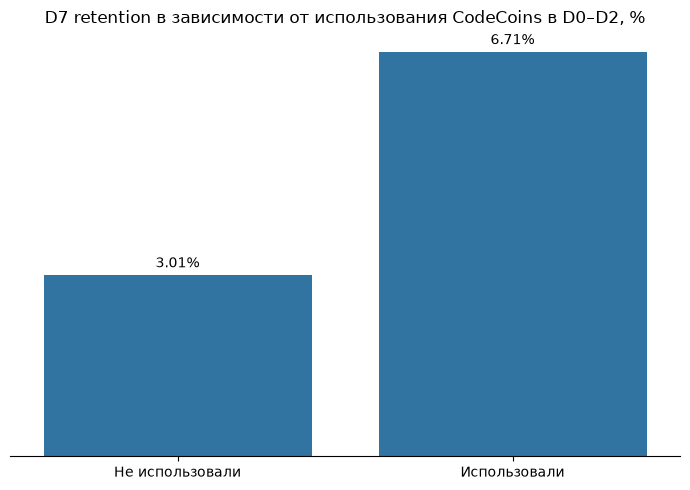

In [73]:
# Подготавливаем понятные названия групп для графика.
codecoins_plot = df_codecoins.copy()

codecoins_plot['Использование CodeCoins'] = (
    codecoins_plot['used_codecoins']
    .map({
        0: 'Не использовали',
        1: 'Использовали'
    })
)

codecoins_plot['d7_retention_pct'] = pd.to_numeric(
    codecoins_plot['d7_retention_pct']
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=codecoins_plot,
    x='Использование CodeCoins',
    y='d7_retention_pct'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=3,
        fontsize=10
    )

plt.title(
    'D7 retention в зависимости от использования CodeCoins в D0–D2, %'
)
plt.xlabel('')
plt.ylabel('')
plt.yticks([])

sns.despine(left=True)

plt.tight_layout()

plt.savefig(
    figures_dir / 'codecoins_retention.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

#### Вывод по H7

Среди пользователей, использовавших CodeCoins для покупки контента в D0–D2, D7 retention составляет 6,71% против 3,01% среди пользователей без таких операций.

Связь статистически значима (χ² = 19,76; p < 0,001), однако Cramér's V = 0,086 указывает на небольшую силу связи.

Таким образом, H7 поддерживается данными: использование CodeCoins в первые три дня связано с более высоким D7 retention. При этом результат не доказывает причинного влияния CodeCoins на удержание. Например, пользователи, которые уже в первые дни приобретают дополнительный контент, могут изначально быть более активными.

<a id='h8'></a>

### 5.8. H8. Время до первого успешного решения и D7 retention

**Гипотеза H8:** более короткое время до первого успешного решения связано с более высоким D7 retention.

Для пользователей, получивших первое успешное решение в D0–D2, рассчитаем время от первого CodeRun успешно решённой задачи до первого успешного CodeSubmit этой же задачи и сравним этот показатель между пользователями, вернувшимися и не вернувшимися на D7.

In [74]:
%%sql time_to_success <<

-- Для пользователей с первым успешным решением в D0–D2 рассчитываем время от первого CodeRun этой задачи
-- до её успешного CodeSubmit.

WITH base_users AS (
    SELECT
        id AS user_id,
        date_joined::date AS registration_date
    FROM users
    WHERE id > 94
),

observation AS (
    SELECT
        MAX(ue.entry_at::date) AS observation_end
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

entries AS (
    SELECT DISTINCT
        ue.user_id,
        ue.entry_at::date AS entry_date
    FROM userentry AS ue
    JOIN base_users AS bu
        ON bu.user_id = ue.user_id
),

-- Находим первое успешное решение каждого пользователя.
first_success AS (
    SELECT DISTINCT ON (cs.user_id)
        cs.user_id,
        bu.registration_date,
        cs.problem_id,
        cs.created_at AS first_success_at
    FROM codesubmit AS cs
    JOIN base_users AS bu
        ON bu.user_id = cs.user_id
    WHERE cs.is_false = 0
    ORDER BY
        cs.user_id,
        cs.created_at
),

-- Оставляем пользователей, получивших первый успех в D0–D2.
early_success AS (
    SELECT *
    FROM first_success
    WHERE first_success_at::date
          BETWEEN registration_date
              AND registration_date + 2
),

-- Для успешно решённой задачи находим первый CodeRun, который произошёл до успешного CodeSubmit.
first_run_same_problem AS (
    SELECT
        es.user_id,
        es.registration_date,
        es.problem_id,
        es.first_success_at,
        MIN(cr.created_at) AS first_run_at
    FROM early_success AS es
    JOIN coderun AS cr
        ON cr.user_id = es.user_id
       AND cr.problem_id = es.problem_id
       AND cr.created_at <= es.first_success_at
    GROUP BY
        es.user_id,
        es.registration_date,
        es.problem_id,
        es.first_success_at
)

SELECT
    fr.user_id,
    ROUND(
        CAST(
            EXTRACT(
                EPOCH FROM (fr.first_success_at - fr.first_run_at)
            ) / 60.0
            AS NUMERIC
        ),
        2
    ) AS minutes_to_success,

    CASE
        WHEN EXISTS (
            SELECT 1
            FROM entries AS e
            WHERE e.user_id = fr.user_id
              AND e.entry_date = fr.registration_date + 7
        )
        THEN 1
        ELSE 0
    END AS retained_d7

FROM first_run_same_problem AS fr
CROSS JOIN observation AS o
WHERE fr.registration_date + 7 <= o.observation_end
ORDER BY fr.user_id;

Преобразуем результат в DataFrame и посмотрим распределение времени до первого успешного решения.

In [75]:
df_time_to_success = time_to_success.DataFrame()

df_time_to_success['minutes_to_success'] = pd.to_numeric(
    df_time_to_success['minutes_to_success']
)

df_time_to_success

,user_id,minutes_to_success,retained_d7
0,98,2.62,1
1,99,40.71,0
2,100,0.85,0
3,101,0.14,0
4,108,2.58,0
...,...,...,...
471,2796,11.60,0
472,2803,520.20,1
473,2804,0.30,0
474,2812,2.50,0


Сначала посмотрим распределение времени до первого успешного решения. Это поможет выбрать подходящий статистический тест для сравнения групп.

In [76]:
df_time_to_success['minutes_to_success'].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
)

count     476.000000
mean       34.559223
std       154.190672
min         0.120000
25%         1.380000
50%         5.140000
75%        14.095000
90%        42.630000
95%        97.230000
max      1838.730000
Name: minutes_to_success, dtype: float64

In [77]:
# Сравниваем время до первого успеха у вернувшихся и не вернувшихся на D7 пользователей.
(
    df_time_to_success
    .groupby('retained_d7')['minutes_to_success']
    .agg(
        users='count',
        median='median',
        mean='mean',
        min='min',
        max='max'
    )
    .round(2)
)

,users,median,mean,min,max
retained_d7,,,,,
0,410,4.94,31.81,0.12,1838.73
1,66,9.03,51.65,0.17,800.99


#### Статистическая проверка H8

Время до первого успешного решения — числовой показатель, однако его распределение сильно скошено: медиана составляет 5,14 минуты, среднее — 34,56 минуты, а максимальное значение превышает 1 800 минут.

Поэтому для сравнения двух независимых групп используем непараметрический критерий Манна — Уитни, который не требует нормального распределения данных.

- **H₀:** распределение времени до первого успешного решения не различается между пользователями, вернувшимися и не вернувшимися на D7.
- **H₁:** распределение времени до первого успешного решения различается между группами.

Уровень значимости: α = 0,05.

In [78]:
# Разделяем пользователей на две независимые группы.
time_retained = df_time_to_success.loc[
    df_time_to_success['retained_d7'] == 1,
    'minutes_to_success'
]

time_not_retained = df_time_to_success.loc[
    df_time_to_success['retained_d7'] == 0,
    'minutes_to_success'
]

# Сравниваем распределения времени до первого успеха.
u_stat, p_value = mannwhitneyu(
    time_retained,
    time_not_retained,
    alternative='two-sided'
)

alpha = 0.05

print(f'U = {u_stat:.0f}')
print(f'p-value = {p_value:.4g}')

if p_value < alpha:
    print(
        'Результат: H₀ отвергается. '
        'Распределение времени до первого успешного решения '
        'статистически значимо различается между группами D7 retention.'
    )
else:
    print(
        'Результат: нет оснований отвергнуть H₀. '
        'Статистически значимых различий во времени до первого '
        'успешного решения между группами не обнаружено.'
    )

U = 15775
p-value = 0.03045
Результат: H₀ отвергается. Распределение времени до первого успешного решения статистически значимо различается между группами D7 retention.


#### Вывод по H8

Среди пользователей, получивших первое успешное решение в D0–D2, медианное время от первого CodeRun успешно решённой задачи до успешного CodeSubmit составляет 4,94 минуты для пользователей, не вернувшихся на D7, и 9,03 минуты для пользователей, вернувшихся на D7.

Критерий Манна — Уитни выявил статистически значимые различия между группами (U = 15 775; p = 0,030). Однако направление различий противоположно исходной гипотезе: пользователи, вернувшиеся на D7, не достигали первого успеха быстрее.

Таким образом, H8 не поддерживается данными. Результат показывает, что связь раннего успешного решения с более высоким retention, обнаруженная в H3, не означает, что первое решение необходимо получить максимально быстро.

Анализ относится только к пользователям, получившим первый успех в D0–D2 и имевшим зафиксированный CodeRun этой же задачи до успешного CodeSubmit — всего 476 пользователей. Результат не позволяет сделать вывод о причинном влиянии времени решения на удержание.

[Вернуться к содержанию](#toc)

<a id='results'></a>

## 6. Основные результаты исследования

Анализ показал, что наиболее заметное снижение активности пользователей происходит в первые дни после регистрации. Проверка гипотез позволила определить, какие особенности раннего поведения связаны с последующим D7 retention.

| Гипотеза | Результат | Основной результат |
|---|---|---|
| **H1. Активность в D0–D2** | Поддерживается | D7 retention растёт с 0,72% при 0 активных днях до 31,11% при активности во все три дня; V = 0,332 |
| **H2. Ранняя работа с задачами** | Поддерживается | D7 retention при раннем CodeRun — 11,14% против 1,92%; при CodeSubmit — 10,94% против 2,06% |
| **H3. Раннее успешное решение** | Поддерживается | D7 retention — 13,04% при раннем успехе против 2,03% без него; V = 0,218 |
| **H4. Неуспешные попытки до первого успеха** | Не поддерживается | Статистически значимых различий не обнаружено (p = 0,358) |
| **H5. Сложность первой задачи** | Не поддерживается | Статистически значимой связи с D7 retention не обнаружено (p = 0,606) |
| **H6. Использование нескольких разделов** | Не поддерживается | D7 retention — 8,26% при использовании двух разделов против 5,46% при использовании одного, но различие статистически незначимо (p = 0,139) |
| **H7. Раннее использование CodeCoins** | Поддерживается | D7 retention — 6,71% против 3,01%; связь статистически значима, но невелика (V = 0,086) |
| **H8. Более короткое время до первого успеха** | Не поддерживается | Вернувшиеся на D7 достигали первого успеха не быстрее: медиана 9,03 против 4,94 минуты; различие статистически значимо (p = 0,030) |

### 6.1. Основной отток происходит в первые дни после регистрации

N-day retention показывает наиболее заметное снижение сразу после регистрации. В день регистрации вход зафиксирован у 83,86% пользователей, на D1 возвращаются 15,66%, на D3 — 7,79%, а на D7 — 4,38%. Далее снижение становится более плавным: D30 retention составляет 1,04%, D60 — 0,84%, D90 — 0,55%.

При этом N-day retention учитывает возвращение пользователя только в конкретный день. Rolling retention показывает, что часть пользователей пропускает контрольный день, но возвращается на платформу позже. Rolling D7 составляет 22,26%, D30 — 13,02%, D60 — 8,55%, D90 — 5,65%.

Таким образом, пользователи IT Resume возвращаются на платформу нерегулярно, поэтому N-day и rolling retention дают разные оценки удержания. Однако обе метрики показывают снижение доли возвращающихся пользователей по мере увеличения времени после регистрации, а наиболее заметное сокращение активности происходит в начале пользовательского пути.

### 6.2. Регулярная активность в первые дни связана с более высоким retention

Наиболее выраженная связь с D7 retention среди рассмотренных категориальных признаков обнаружена для количества активных дней в D0–D2.

D7 retention составляет 0,72% среди пользователей без зафиксированной активности в первые три дня, 1,98% — среди активных в один день, 10,16% — среди активных в два дня и 31,11% — среди пользователей, активных во все три дня.

Связь статистически значима (p < 0,001), Cramér's V = 0,332.

Таким образом, пользователи, которые возвращаются на платформу несколько раз в первые дни после регистрации, значительно чаще возвращаются и на D7. При этом результат показывает связь между признаками, но не позволяет утверждать, что именно увеличение количества активных дней само по себе приводит к росту retention.

### 6.3. Работа с задачами и первый успешный результат связаны с удержанием

Пользователи, которые начинают работать с задачами в D0–D2, имеют более высокий D7 retention.

Среди пользователей с ранним CodeRun D7 retention составляет 11,14% против 1,92% среди пользователей без CodeRun. Для CodeSubmit показатели составляют 10,94% и 2,06% соответственно. В обоих случаях связь статистически значима (p < 0,001).

Получение успешного решения в первые три дня также связано с более высоким удержанием. D7 retention пользователей с ранним успешным CodeSubmit составляет 13,04% против 2,03% среди пользователей без раннего успеха (p < 0,001; Cramér's V = 0,218).

При этом использование большего количества разделов платформы само по себе не показало статистически значимой связи с D7 retention. Среди пользователей, работавших только с задачами, D7 retention составляет 11,17%, тогда как среди использовавших только тесты — 1,76%.

Результаты показывают, что для последующего удержания характер ранней активности может быть важнее количества используемых разделов. В частности, работа с задачами и получение первого успешного результата связаны с более высоким D7 retention.

### 6.4. Скорость и простота первого успеха не показали ожидаемой связи

Дополнительный анализ не подтвердил предположение о том, что первый успешный результат обязательно должен достигаться быстрее или на более простой задаче.

Количество неуспешных попыток до первого успешного решения статистически значимо не различается между пользователями, вернувшимися и не вернувшимися на D7 (p = 0,358).

Не обнаружена и статистически значимая связь между сложностью первой задачи и D7 retention (p = 0,606). Retention составляет 11,29% для пользователей, начавших с задачи сложности 1, 11,76% — сложности 2 и 7,69% — сложности 3.

Гипотеза о более коротком времени до первого успеха также не поддерживается. Среди пользователей с ранним успешным решением медианное время от первого CodeRun успешно решённой задачи до успешного CodeSubmit составляет 9,03 минуты для вернувшихся на D7 и 4,94 минуты для не вернувшихся. Различие статистически значимо (p = 0,030), но его направление противоположно исходной гипотезе.

Таким образом, данные поддерживают связь самого факта раннего успешного решения с D7 retention, но не подтверждают, что для повышения удержания первая задача обязательно должна быть максимально простой или решаться максимально быстро.

### 6.5. CodeCoins связаны с retention, но связь невелика

Среди пользователей, использовавших CodeCoins для покупки контента в D0–D2, D7 retention составляет 6,71% против 3,01% среди пользователей без таких операций.

Связь статистически значима (p < 0,001), однако Cramér's V = 0,086 указывает на небольшую силу связи.

Поэтому раннее использование CodeCoins можно рассматривать как дополнительный признак вовлечённости пользователя, но полученный результат не позволяет утверждать, что именно использование внутренней валюты приводит к более высокому retention. Пользователи, приобретающие дополнительный контент в первые дни, могут изначально быть более активными.

### 6.6. Retention различается между когортами регистрации

Когортный анализ показал заметные различия в удержании пользователей разных месяцев регистрации.

С ноября 2021 года по февраль 2022 года D1 retention последовательно снижается с 27,27% до 12,29%. Февральская когорта при этом является самой крупной — 1 058 пользователей — и показывает низкие значения retention на большинстве контрольных дней: D7 — 2,08%, D14 — 1,23%, D30 — 0,38%.

В марте показатели начинают расти, а в апрельской когорте D1 retention составляет 18,99%, D7 — 7,59%, D14 — 5,49%, D30 — 3,80%.

Однако по имеющимся данным нельзя определить причины этих изменений только по месяцу регистрации. Различия могут быть связаны с составом аудитории, источниками привлечения, изменениями продукта или другими факторами, информация о которых отсутствует в анализируемых данных.

Поэтому когортные различия необходимо учитывать при интерпретации общих показателей retention и дальнейшем мониторинге продукта.

[Вернуться к содержанию](#toc)

<a id='conclusions'></a>

## 7. Выводы

Анализ показал, что наиболее заметное снижение активности пользователей IT Resume происходит в первые дни после регистрации. N-day retention снижается с 15,66% на D1 до 4,38% на D7 и 1,04% на D30. При этом rolling retention заметно выше: 22,26% на D7 и 13,02% на D30. Это показывает, что часть пользователей возвращается на платформу нерегулярно и может пропускать конкретные контрольные дни.

С более высоким D7 retention наиболее заметно связана регулярная активность в первые три дня после регистрации. Более высокий retention также наблюдается среди пользователей, которые в этот период начинают работать с задачами и получают первое успешное решение. При этом использование большего количества разделов платформы само по себе не показало статистически значимой связи с удержанием.

Дополнительный анализ не подтвердил предположение о том, что первый успешный результат обязательно должен быть получен максимально быстро или на более простой задаче. Статистически значимой связи D7 retention со сложностью первой задачи и количеством неуспешных попыток до первого успеха не обнаружено. Пользователи, вернувшиеся на D7, также не достигали первого успешного решения быстрее.

В совокупности результаты показывают потенциальное направление для развития продукта: помочь новому пользователю вернуться на платформу в первые дни, начать работу с задачами и получить первый успешный результат. При этом обнаруженные зависимости являются статистическими связями и не доказывают причинного влияния исследованных факторов на retention. Предлагаемые изменения необходимо проверять с помощью продуктовых экспериментов.

<a id='recommendations'></a>

## 8. Продуктовые рекомендации

Результаты анализа показывают, что основные возможности для улучшения удержания связаны с первыми днями после регистрации, ранним переходом к работе с задачами и получением первого успешного результата.

Поскольку проведённый анализ выявляет статистические связи, но не доказывает причинное влияние отдельных действий на retention, предложенные изменения следует рассматривать как продуктовые гипотезы и проверять с помощью A/B-тестов.

### 8.1. Стимулировать повторное возвращение в первые дни после регистрации

Количество активных дней в D0–D2 показало наиболее выраженную связь с D7 retention среди рассмотренных категориальных признаков. D7 retention увеличивается с 0,72% среди пользователей без активности в этот период до 31,11% среди пользователей, активных во все три дня.

При этом rolling retention показывает, что пользователи могут возвращаться на платформу нерегулярно. Поэтому задача продукта состоит не в том, чтобы добиться обязательного ежедневного посещения, а в том, чтобы стимулировать повторное взаимодействие с платформой после первого визита.

Можно протестировать:
- напоминание в D1–D2 о незавершённой или следующей задаче;
- персональную рекомендацию следующей задачи на основе первых действий пользователя;
- короткий план первых шагов после регистрации, распределённый на несколько посещений;
- бонус CodeCoins за повторное возвращение на платформу в D1–D2;
- небольшой бонус CodeCoins за первое успешное решение задачи.

**Основные метрики эксперимента:** D7 retention и Rolling D7.

**Дополнительные метрики:** D1 retention, D3 retention и количество активных дней в D0–D2.

### 8.2. Сократить путь от регистрации до первой задачи

Ранняя работа с задачами связана с более высоким D7 retention. Среди пользователей с CodeRun в D0–D2 D7 retention составляет 11,14% против 1,92% среди пользователей без раннего CodeRun. Для CodeSubmit показатели составляют 10,94% и 2,06% соответственно.

При этом использование нескольких разделов платформы само по себе не показало статистически значимой связи с удержанием. Это позволяет проверить гипотезу о том, что на старте пользователю полезнее быстрее перейти к содержательной работе с задачей, чем одновременно знакомиться со всеми возможностями платформы.

В onboarding можно протестировать более короткий путь от регистрации к первой подходящей задаче: сделать её основным следующим действием и сократить количество промежуточных шагов, так же можно сделать первую задачу более интерактивной.

**Основная метрика эксперимента:** D7 retention.

**Дополнительные метрики:** доля пользователей с CodeRun и CodeSubmit в D0–D2 и время от регистрации до первого CodeRun.

### 8.3. Помочь пользователю получить первый успешный результат

Получение успешного решения в D0–D2 связано с более высоким D7 retention: 13,04% против 2,03% среди пользователей без раннего успешного решения.

При этом анализ не показал, что первый успех обязательно должен достигаться максимально быстро или на самой простой задаче. Статистически значимой связи retention со сложностью первой задачи и количеством неуспешных попыток до первого успеха не обнаружено, а пользователи, вернувшиеся на D7, не достигали первого успешного решения быстрее.

Поэтому можно проверить сценарий, в котором пользователю помогают дойти до первого содержательного успешного решения, не упрощая задачу искусственно. Например, протестировать подбор стартовой задачи с учётом уровня пользователя, постепенные подсказки при затруднении и более понятную обратную связь после неуспешного CodeSubmit (судя по общей платформе связь может идти через пройденные после загрузки решения тесты, там дан только сравнительный анализ результата пользователя и ожидаемого результата, в чем конкретно ошибка - непонятно).

**Основная метрика эксперимента:** D7 retention.

**Дополнительные метрики:** доля пользователей с успешным CodeSubmit в D0–D2, доля пользователей, начавших задачу, но не дошедших до успешного решения, и использование подсказок.

### 8.4. Проверить роль CodeCoins в раннем вовлечении

Раннее использование CodeCoins для покупки контента связано с более высоким D7 retention: 6,76% против 2,99%. Связь статистически значима, но невелика (Cramér's V = 0,087).

Кроме того, использование CodeCoins может быть не причиной более высокого retention, а следствием большей исходной активности пользователя. Поэтому CodeCoins целесообразно рассматривать как дополнительное направление для экспериментов.

Можно протестировать знакомство с возможностями CodeCoins в первые дни или использование приветственных CodeCoins для следующего полезного действия на платформе.

**Основная метрика эксперимента:** D7 retention.

**Дополнительные метрики:** доля пользователей, использовавших CodeCoins в D0–D2, и переход к работе с задачами после использования CodeCoins.

### 8.5. Приоритет тестирования продуктовых гипотез

Продуктовые эксперименты можно проводить последовательно:

1. **Повторное возвращение в первые дни.** Регулярность активности в D0–D2 показала наиболее выраженную связь с D7 retention среди рассмотренных категориальных признаков. В первую очередь стоит проверить способы стимулировать повторное взаимодействие пользователя с платформой после регистрации.

2. **Сокращение пути до первой задачи.** Ранняя работа с задачами устойчиво связана с более высоким D7 retention, тогда как использование большего количества разделов само по себе такой связи не показало.

3. **Поддержка первого успешного решения.** Ранний успешный CodeSubmit связан с более высоким retention. При этом результаты не подтверждают необходимость искусственно снижать сложность первой задачи или максимально сокращать время её решения.

4. **Эксперименты с CodeCoins.** Связь раннего использования CodeCoins с D7 retention обнаружена, но она заметно слабее, поэтому это направление целесообразно проверять после основных сценариев раннего вовлечения.

[Вернуться к содержанию](#toc)